# DATA 621 Homework 4: Auto Insurance Crash Risk & Claim Cost

## Project Objective
This project uses a training set of roughly 8,000 auto insurance customers to build:

- **Binary logistic regression models** that predict `TARGET_FLAG` (1 = the customer's car was in a crash, 0 = no crash), and
- **Multiple linear regression models** that predict `TARGET_AMT` (the cost of the crash; 0 when there was no crash).

We will then select the best model of each type and use it to score the evaluation data set (probabilities, 0.5-threshold classifications, and predicted cost). Only the supplied variables, or variables derived from them, may be used (`INDEX` is an identifier and is excluded).

**Notebook roadmap:** 1. Load Data / EDA, 2. Data Preparation, 3. Build Models, 4. Select Models & Predictions.

# 1. Load Data/EDA
## 1.1 Dataset Overview & Data Quality Assessment

We start by importing the core libraries and loading the training and evaluation files. Before modeling we verify the size, scope and integrity of the data: how many customers and variables we have, how each variable is stored, and which values are missing.

The raw file stores dollar amounts as text (e.g. `$67,349`) and many categorical levels carry a `z_` prefix (e.g. `z_High School`). We convert the dollar columns to numbers up front so they can be summarized; the categorical labels are left untouched until the data preparation step.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

base_url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/main/homeworks/hw04/data/"
local_dir = "../data/"

def load_csv(name):
    # Use the GitHub copy when available; fall back to the local file (e.g. before the data is merged to main)
    try:
        return pd.read_csv(base_url + name)
    except Exception:
        return pd.read_csv(local_dir + name)

train_df = load_csv("insurance_training_data.csv")
eval_df = load_csv("insurance-evaluation-data.csv")

# Dollar columns are stored as text such as "$67,349"
money_cols = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM"]
for df in (train_df, eval_df):
    for col in money_cols:
        df[col] = pd.to_numeric(df[col].str.replace(r"[$,]", "", regex=True), errors="coerce")

print(f"Training set:   {train_df.shape[0]:,} customers x {train_df.shape[1]} variables")
print(f"Evaluation set: {eval_df.shape[0]:,} customers x {eval_df.shape[1]} variables")
train_df.head()

Training set:   8,161 customers x 26 variables
Evaluation set: 2,141 customers x 26 variables


,INDEX,TARGET_FLAG,TARGET_AMT,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,SEX,EDUCATION,JOB,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CAR_AGE,URBANICITY
0,1,0,0.0,0,60.0,0,11.0,67349.0,No,0.0,z_No,M,PhD,Professional,14,Private,14230,11,Minivan,yes,4461,2,No,3,18.0,Highly Urban/ Urban
1,2,0,0.0,0,43.0,0,11.0,91449.0,No,257252.0,z_No,M,z_High School,z_Blue Collar,22,Commercial,14940,1,Minivan,yes,0,0,No,0,1.0,Highly Urban/ Urban
2,4,0,0.0,0,35.0,1,10.0,16039.0,No,124191.0,Yes,z_F,z_High School,Clerical,5,Private,4010,4,z_SUV,no,38690,2,No,3,10.0,Highly Urban/ Urban
3,5,0,0.0,0,51.0,0,14.0,NaN,No,306251.0,Yes,M,<High School,z_Blue Collar,32,Private,15440,7,Minivan,yes,0,0,No,0,6.0,Highly Urban/ Urban
4,6,0,0.0,0,50.0,0,NaN,114986.0,No,243925.0,Yes,z_F,PhD,Doctor,36,Private,18000,1,z_SUV,no,19217,2,Yes,3,17.0,Highly Urban/ Urban


In [2]:
# Variable types and missing values
cat_cols = train_df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in train_df.select_dtypes(include="number").columns if c not in ("INDEX", "TARGET_FLAG", "TARGET_AMT")]

print(f"{len(num_cols)} numeric predictors: {num_cols}\n")
print(f"{len(cat_cols)} categorical predictors: {cat_cols}\n")

missing = pd.DataFrame({
    "missing": train_df.isnull().sum(),
    "pct_missing": (train_df.isnull().mean() * 100).round(2),
    "eval_pct_missing": (eval_df.isnull().mean() * 100).round(2),
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
display(missing)

13 numeric predictors: ['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'HOME_VAL', 'TRAVTIME', 'BLUEBOOK', 'TIF', 'OLDCLAIM', 'CLM_FREQ', 'MVR_PTS', 'CAR_AGE']

10 categorical predictors: ['PARENT1', 'MSTATUS', 'SEX', 'EDUCATION', 'JOB', 'CAR_USE', 'CAR_TYPE', 'RED_CAR', 'REVOKED', 'URBANICITY']



,missing,pct_missing,eval_pct_missing
JOB,526,6.45,6.49
CAR_AGE,510,6.25,6.03
HOME_VAL,464,5.69,5.18
YOJ,454,5.56,4.39
INCOME,445,5.45,5.84
AGE,6,0.07,0.05


## 1.2 The Target Variables & Baseline Statistics

There are two responses. `TARGET_FLAG` is binary, so we check how balanced it is. `TARGET_AMT` is zero for customers without a crash, so we look at its distribution among crashed customers only, which is what the cost model has to explain.

TARGET_FLAG: 73.6% no crash (0) | 26.4% crash (1)

Crash cost (TARGET_AMT > 0, n=2,153):
count      2153.00
mean       5702.18
std        7743.18
min          30.28
25%        2609.78
50%        4104.00
75%        5787.00
max      107586.14
Skewness: 5.64
TARGET_AMT > 0 only when TARGET_FLAG = 1: True


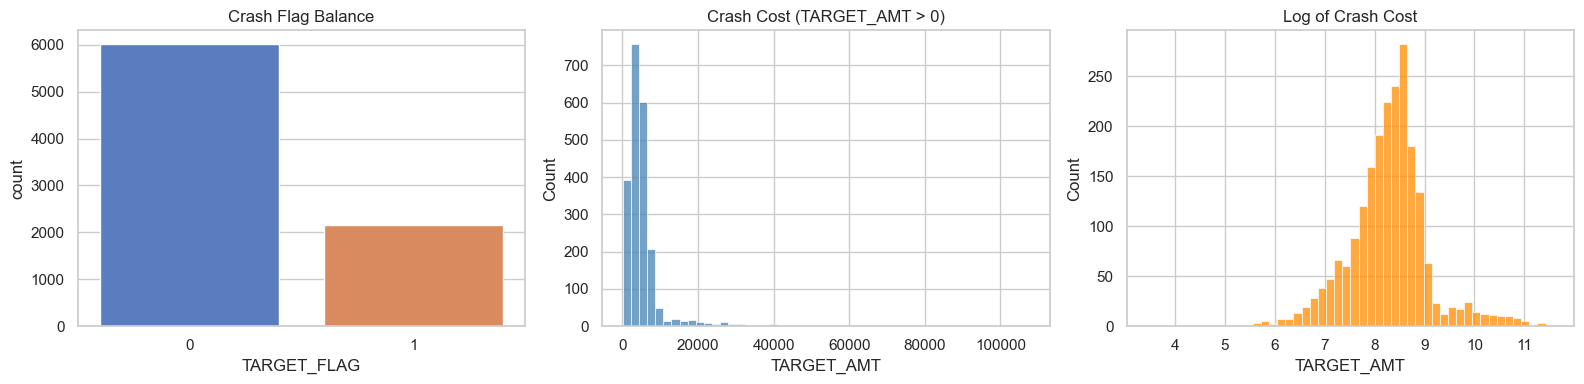

In [3]:
# TARGET_FLAG balance
flag_pct = train_df["TARGET_FLAG"].value_counts(normalize=True).mul(100)
print(f"TARGET_FLAG: {flag_pct[0]:.1f}% no crash (0) | {flag_pct[1]:.1f}% crash (1)")

# TARGET_AMT among crashes
crash_amt = train_df.loc[train_df["TARGET_FLAG"] == 1, "TARGET_AMT"]
print(f"\nCrash cost (TARGET_AMT > 0, n={len(crash_amt):,}):")
print(crash_amt.describe().round(2).to_string())
print(f"Skewness: {crash_amt.skew():.2f}")
print(f"TARGET_AMT > 0 only when TARGET_FLAG = 1: {((train_df['TARGET_AMT'] > 0) == (train_df['TARGET_FLAG'] == 1)).all()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="TARGET_FLAG", data=train_df, hue="TARGET_FLAG", palette="muted", legend=False, ax=axes[0])
axes[0].set_title("Crash Flag Balance")
sns.histplot(crash_amt, bins=50, ax=axes[1], color="steelblue")
axes[1].set_title("Crash Cost (TARGET_AMT > 0)")
sns.histplot(np.log1p(crash_amt), bins=50, ax=axes[2], color="darkorange")
axes[2].set_title("Log of Crash Cost")
plt.tight_layout()
plt.show()

In [4]:
# Mean / standard deviation / median for numeric variables
summary = train_df[num_cols + ["TARGET_AMT"]].agg(["mean", "median", "std", "min", "max", "skew"]).round(2).T
display(summary)

,mean,median,std,min,max,skew
KIDSDRIV,0.17,0.0,0.51,0.0,4.00,3.35
AGE,44.79,45.0,8.63,16.0,81.00,-0.03
HOMEKIDS,0.72,0.0,1.12,0.0,5.00,1.34
YOJ,10.50,11.0,4.09,0.0,23.00,-1.20
INCOME,61898.09,54028.0,47572.68,0.0,367030.00,1.19
HOME_VAL,154867.29,161160.0,129123.77,0.0,885282.00,0.49
TRAVTIME,33.49,33.0,15.91,5.0,142.00,0.45
BLUEBOOK,15709.90,14440.0,8419.73,1500.0,69740.00,0.79
TIF,5.35,4.0,4.15,1.0,25.00,0.89
OLDCLAIM,4037.08,0.0,8777.14,0.0,57037.00,3.12


Only 26.4% of customers crashed, so the classes are imbalanced (about 3:1) but not extreme; we will judge the classifier on precision, sensitivity and AUC rather than accuracy alone. Crash costs are strongly right-skewed (median about $4,100, mean about $5,700, maximum about $107,600), so the cost model will likely benefit from a log transform or from being fit on crashed customers only.

## 1.3 Distributions of the Predictors

Box plots and bar charts show which variables are skewed, contain outliers, or have implausible values that will need attention in data preparation.

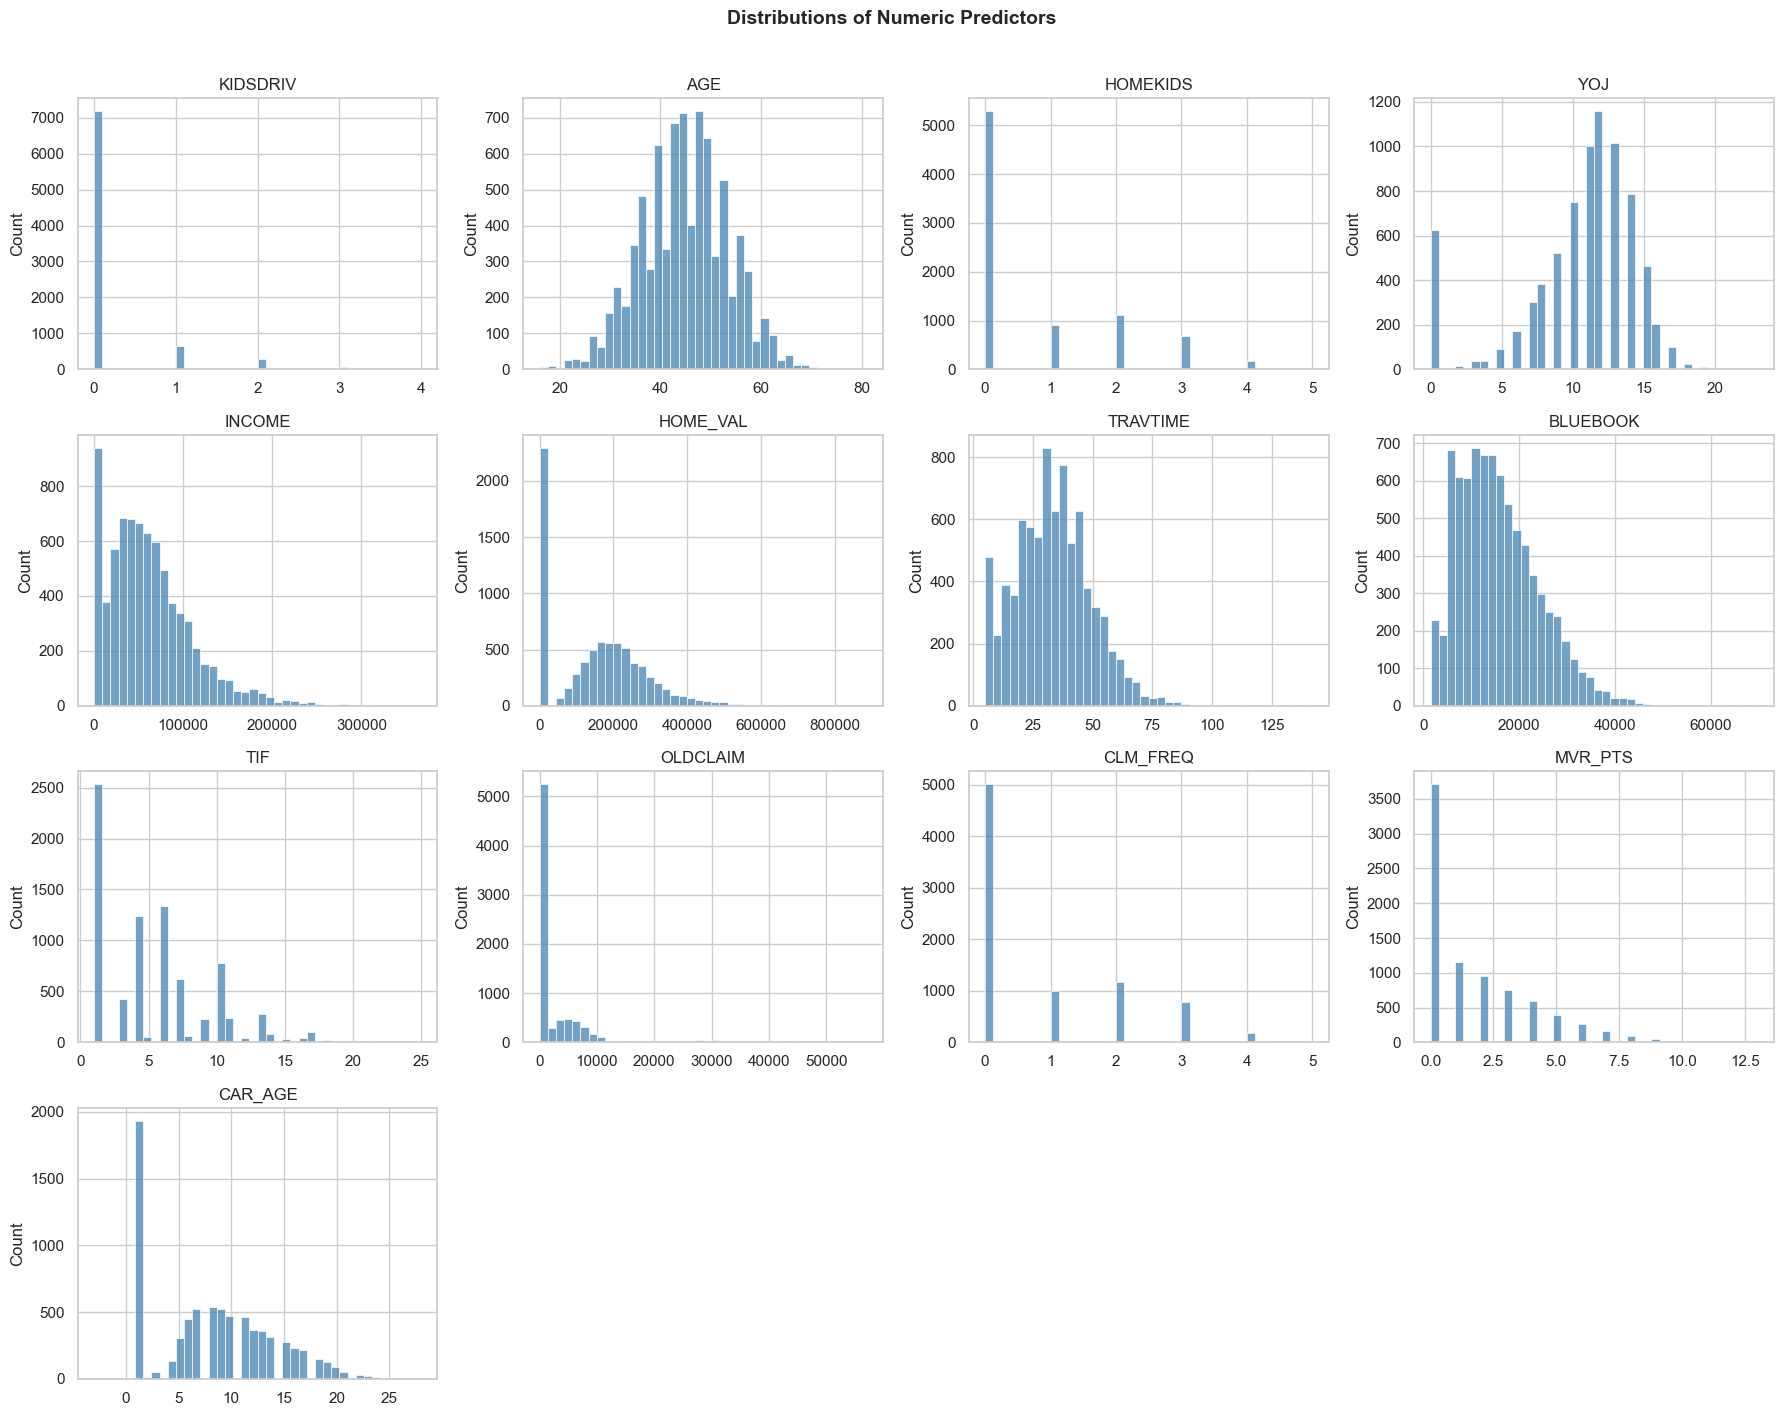

In [5]:
# Numeric predictors: histograms
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(train_df[col].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle("Distributions of Numeric Predictors", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

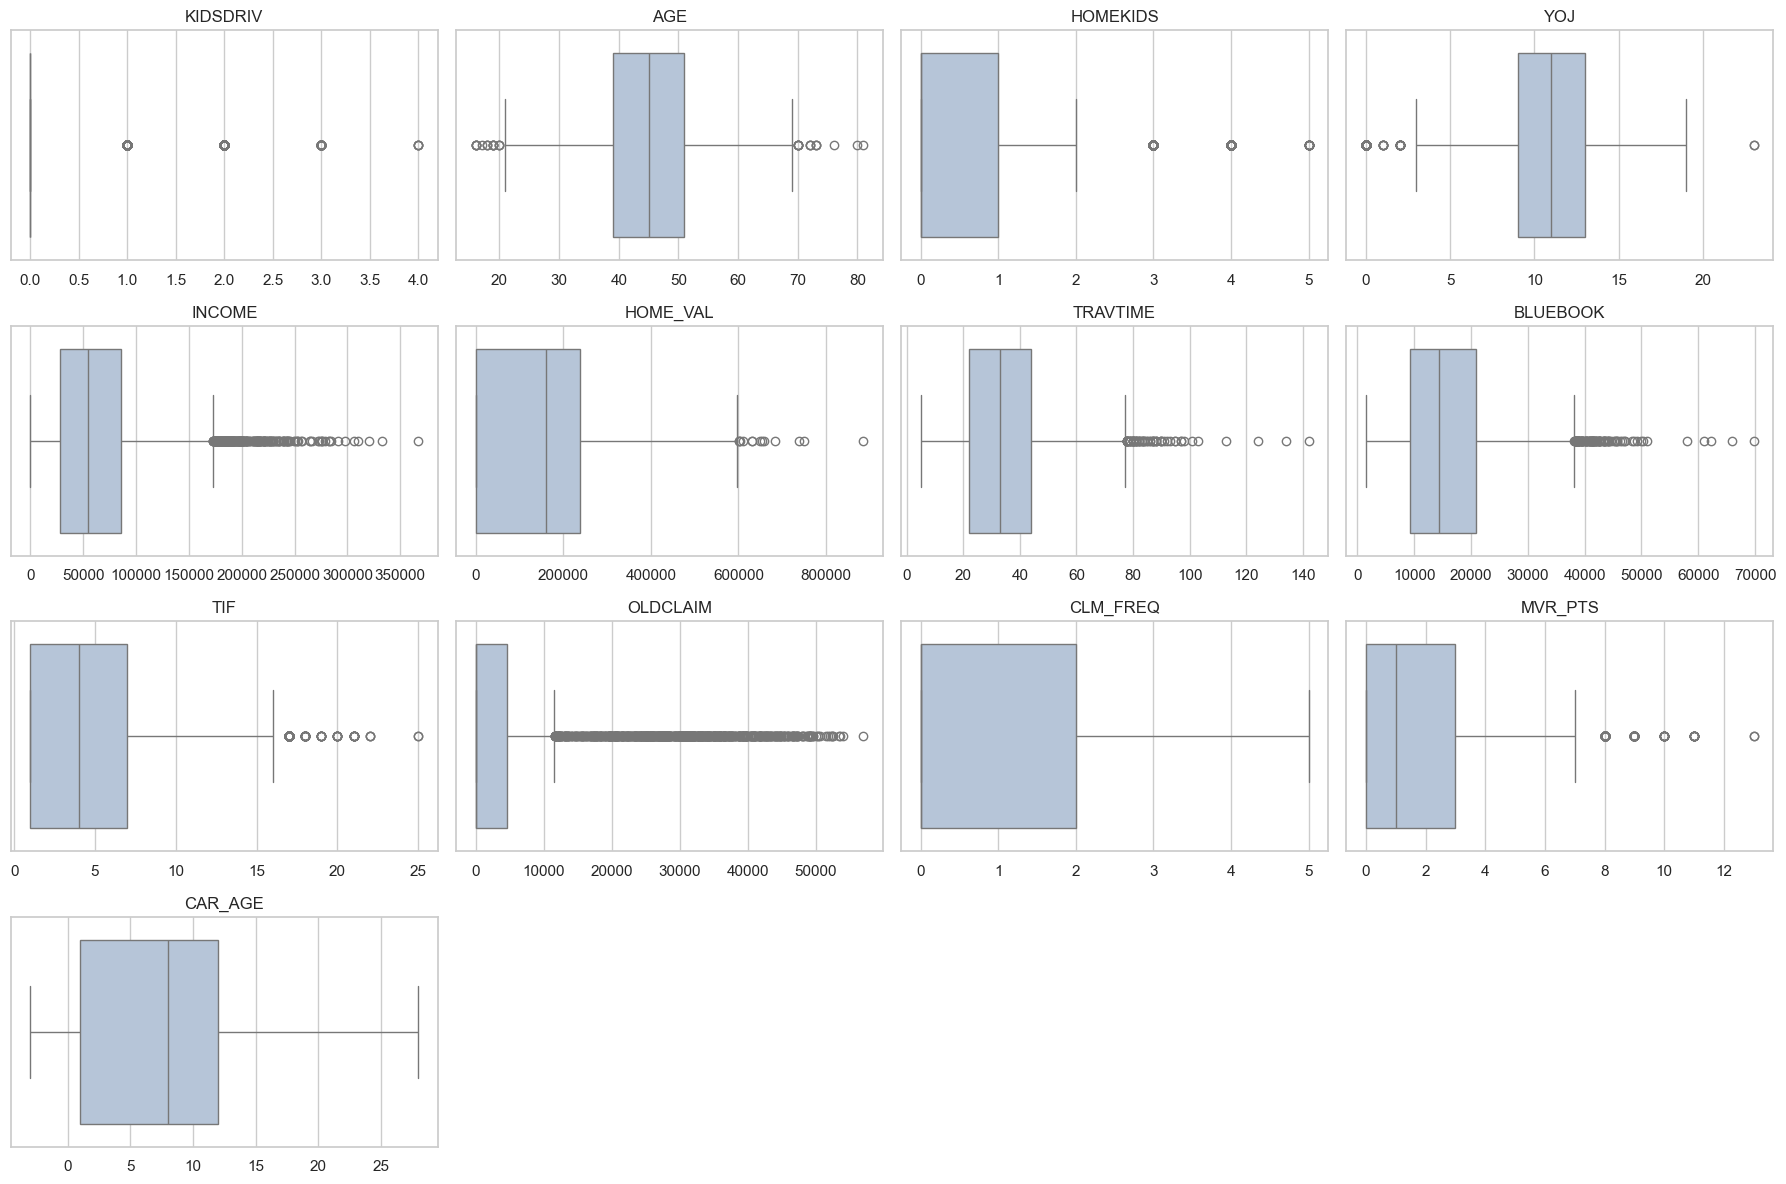

Negative CAR_AGE values: 1
Zero-valued HOME_VAL (likely renters): 2294
Zero-valued INCOME: 615
Age range: 16.0 - 81.0


In [6]:
# Outlier view: box plots of the numeric predictors
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=train_df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# Values that look suspicious
print("Negative CAR_AGE values:", (train_df["CAR_AGE"] < 0).sum())
print("Zero-valued HOME_VAL (likely renters):", (train_df["HOME_VAL"] == 0).sum())
print("Zero-valued INCOME:", (train_df["INCOME"] == 0).sum())
print("Age range:", train_df["AGE"].min(), "-", train_df["AGE"].max())

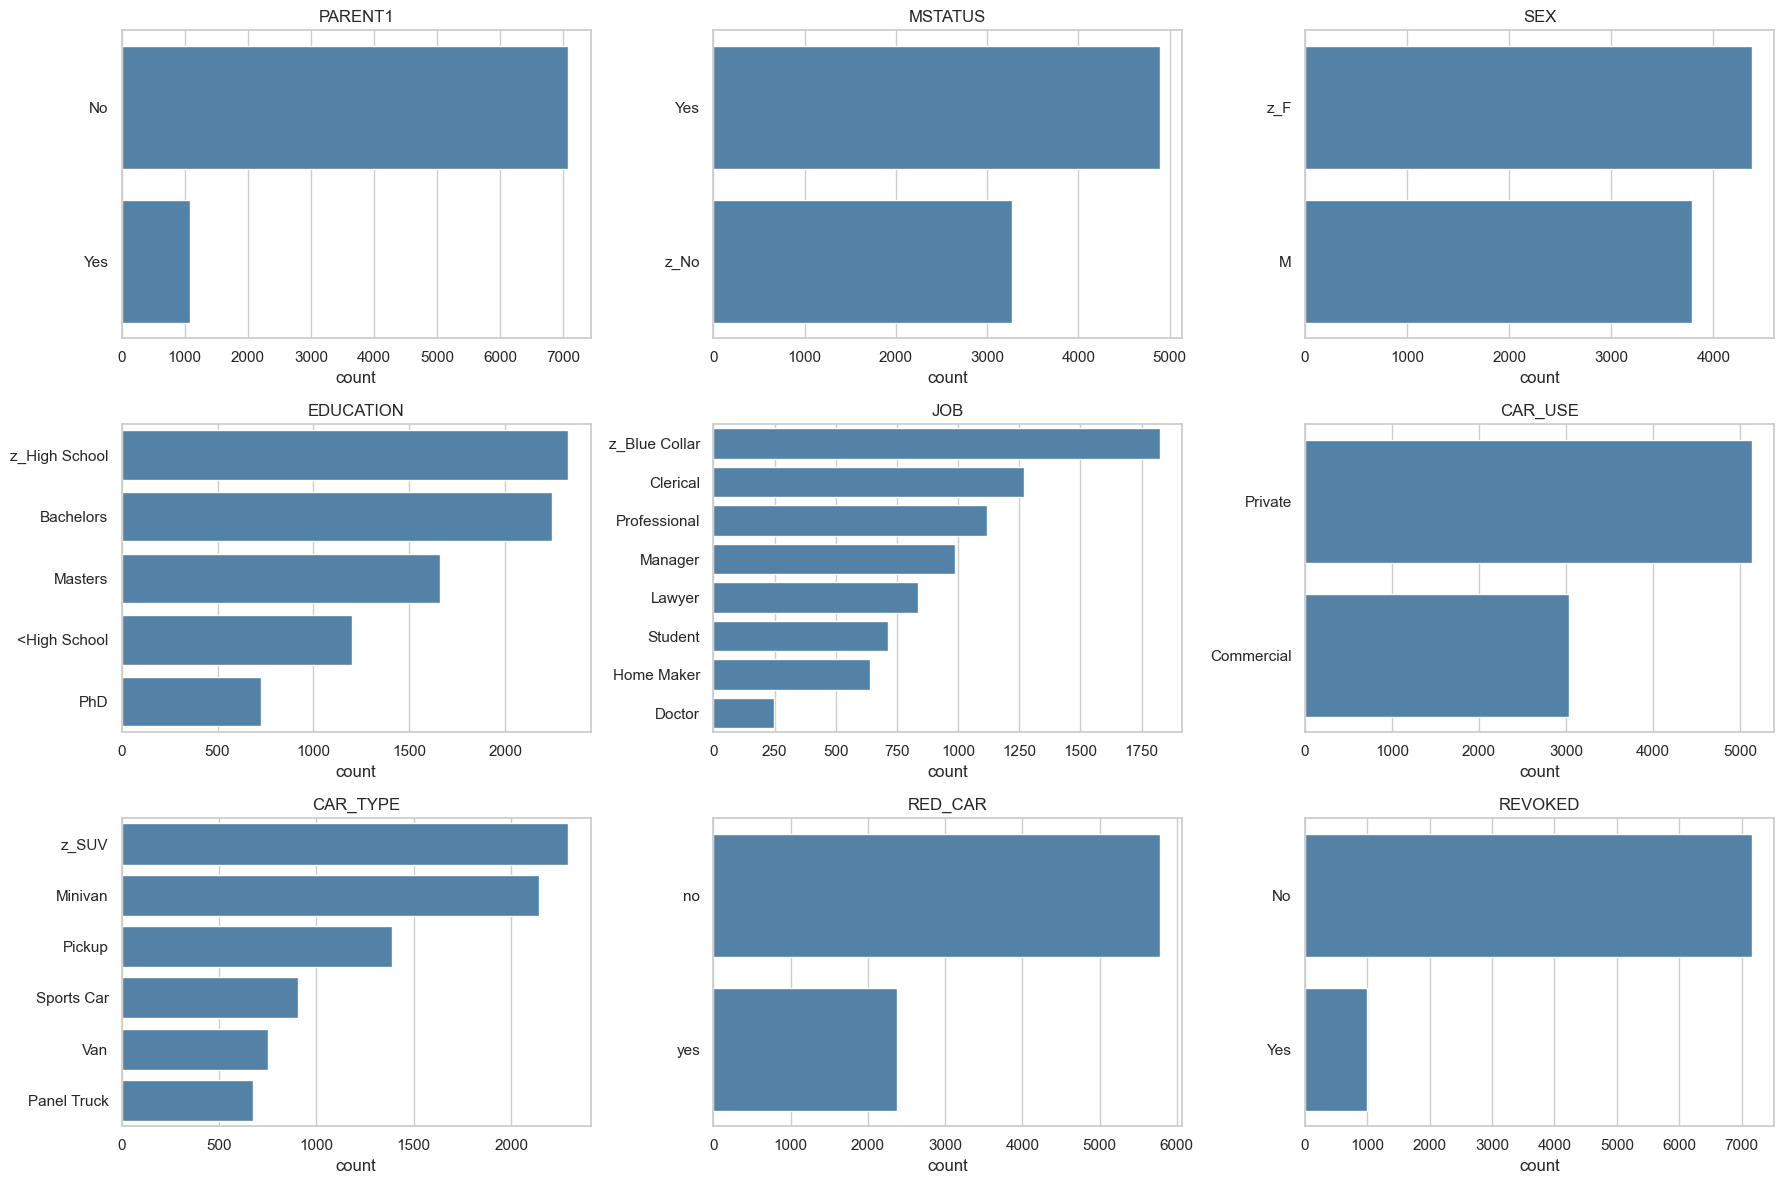

In [7]:
# Categorical predictors: counts per level
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    order = train_df[col].value_counts().index
    sns.countplot(y=col, data=train_df, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

`KIDSDRIV`, `OLDCLAIM`, `HOMEKIDS`, `CLM_FREQ` and `MVR_PTS` are zero-heavy and right-skewed, and `INCOME`, `HOME_VAL` and `BLUEBOOK` have long right tails. `HOME_VAL` is 0 for 2,294 customers (likely renters) and `INCOME` is 0 for 615, so zeros are meaningful values rather than missing data. `CAR_AGE` has a single impossible negative value (-3). The categorical variables carry inconsistent `z_` prefixes on some levels that should be cleaned.

## 1.4 Relationship with the Targets

We now look at which variables separate crashed from non-crashed customers, and at the crash rate within each categorical level, to compare against the theoretical effects given in the assignment.

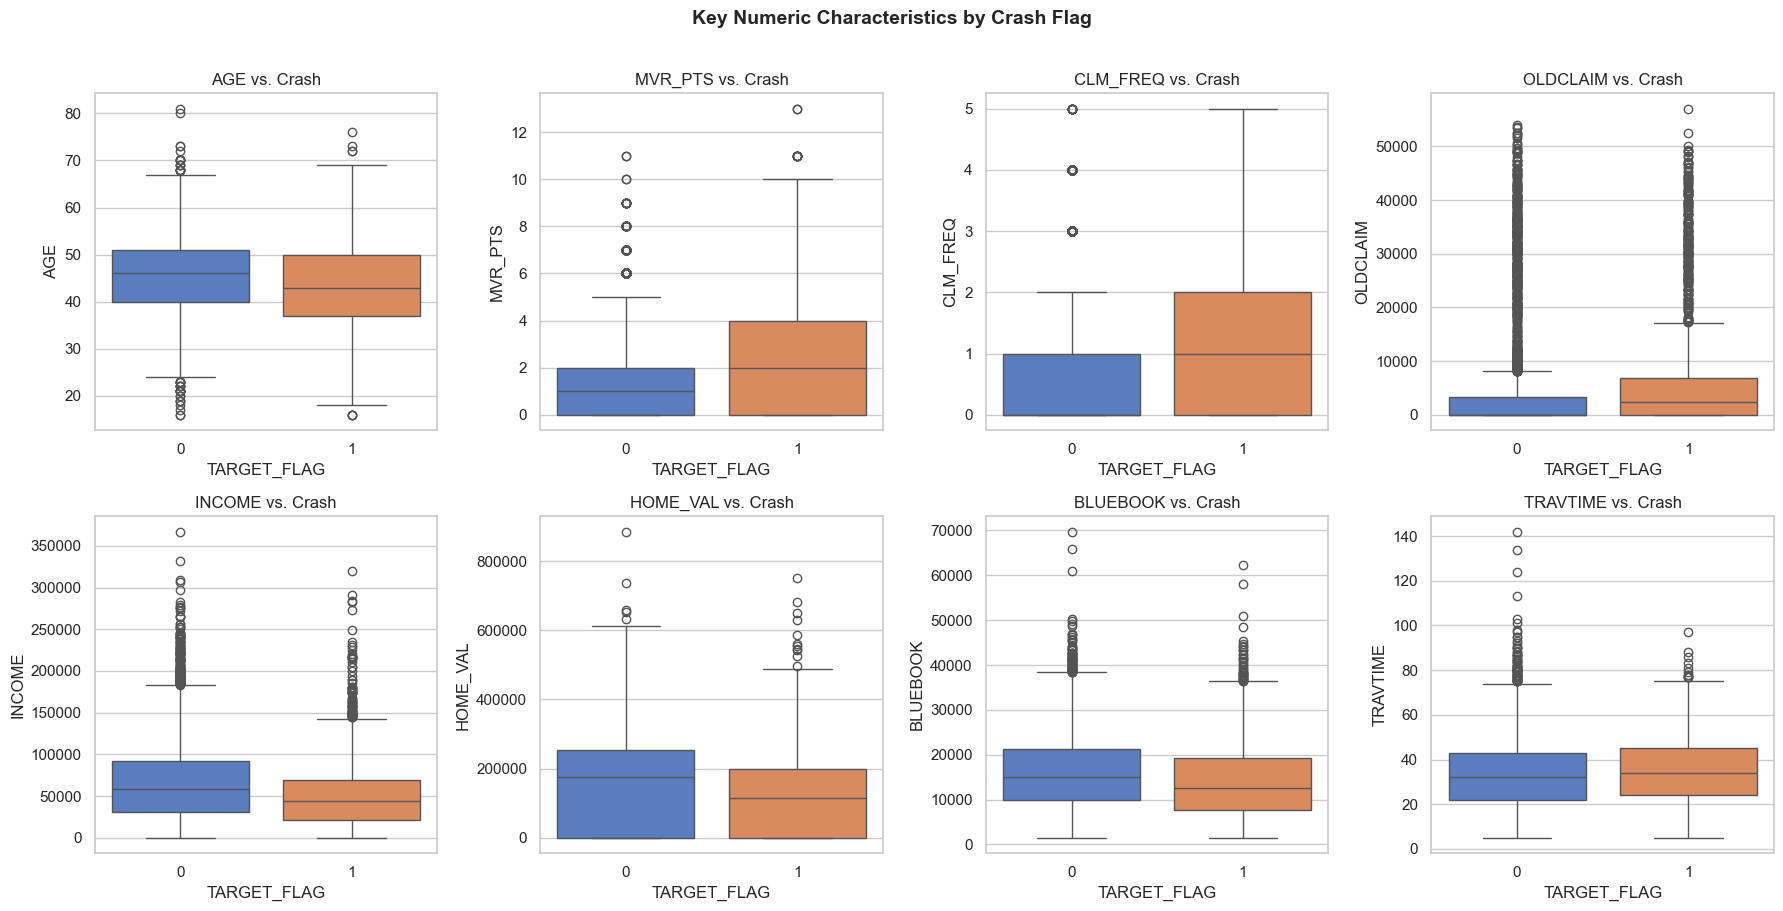

In [8]:
# Numeric predictors by crash flag
key_num = ["AGE", "MVR_PTS", "CLM_FREQ", "OLDCLAIM", "INCOME", "HOME_VAL", "BLUEBOOK", "TRAVTIME"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(x="TARGET_FLAG", y=col, data=train_df, hue="TARGET_FLAG", palette="muted", legend=False, ax=ax)
    ax.set_title(f"{col} vs. Crash")
plt.suptitle("Key Numeric Characteristics by Crash Flag", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

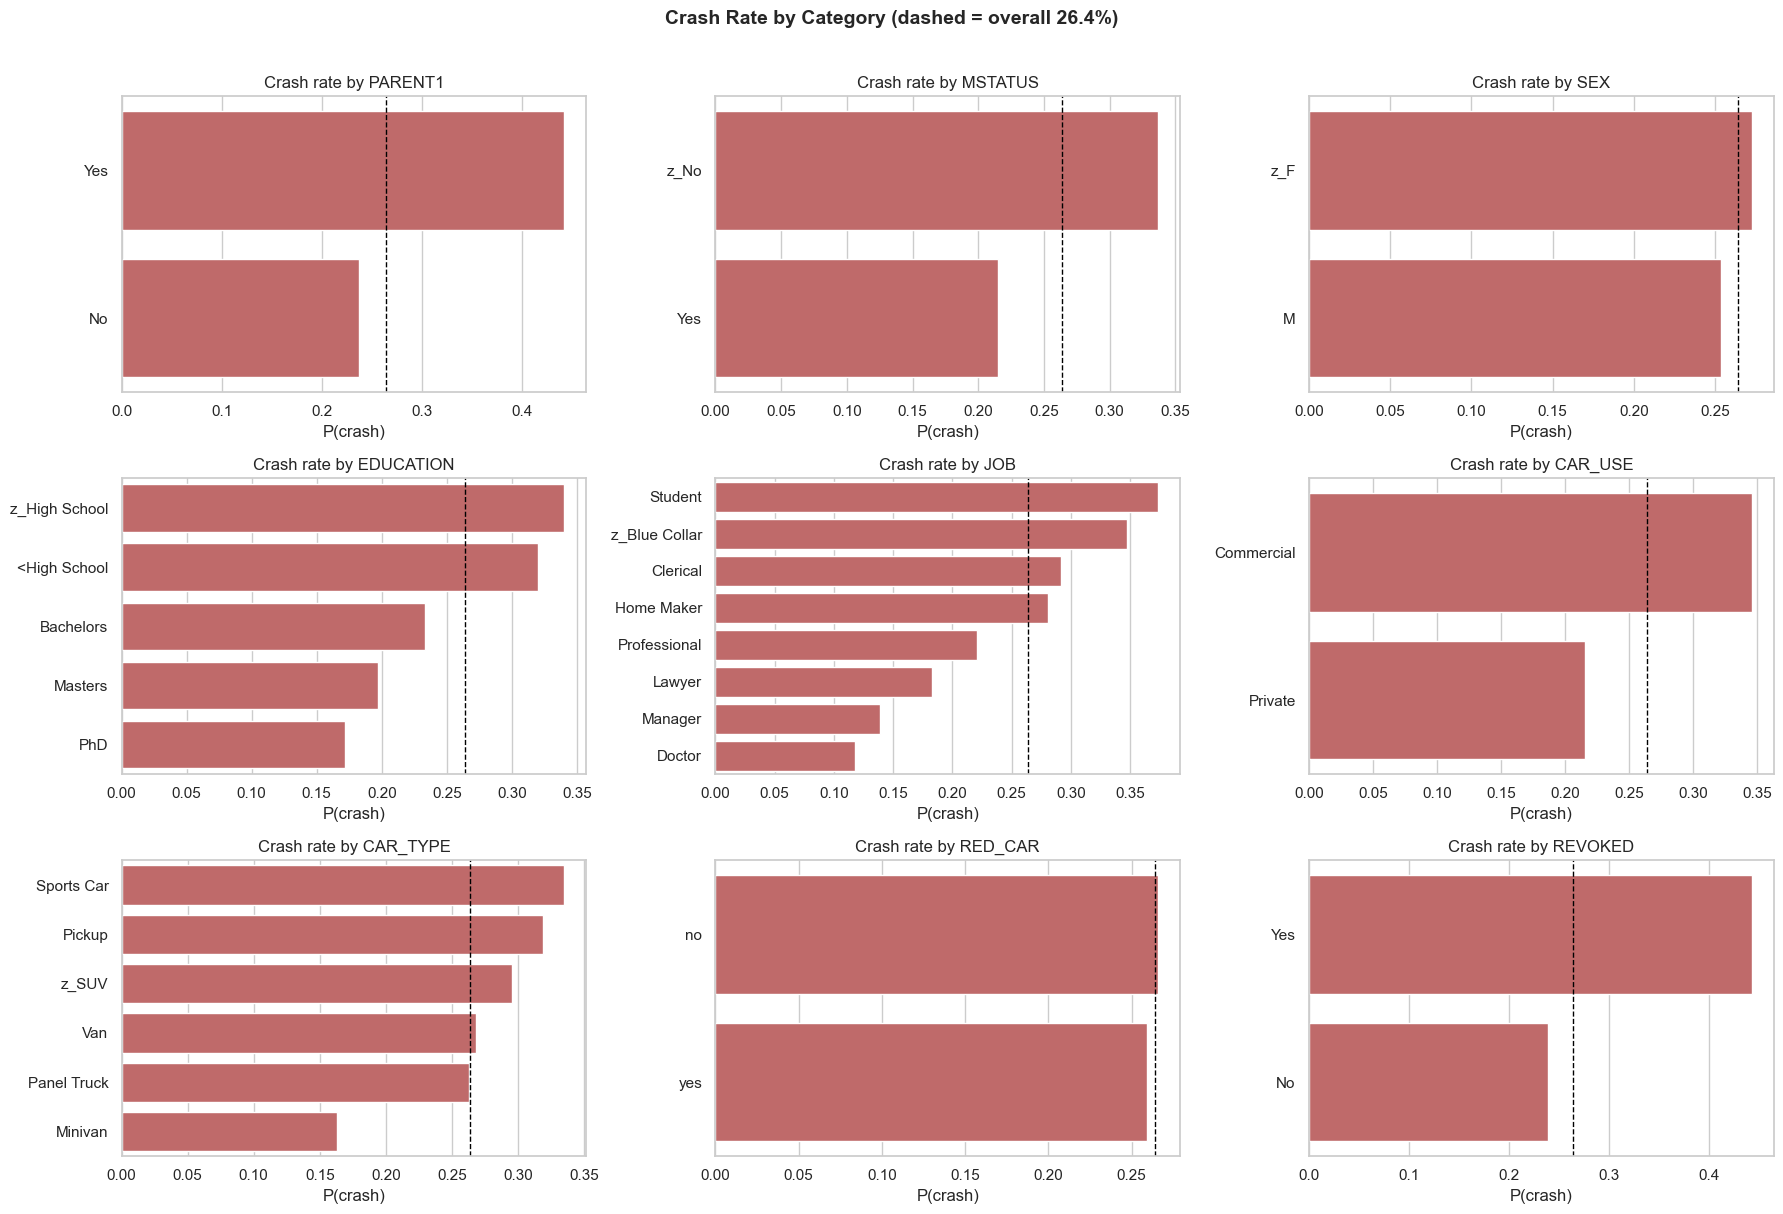

In [9]:
# Crash rate by categorical level
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
overall = train_df["TARGET_FLAG"].mean()
for ax, col in zip(axes.ravel(), cat_cols):
    rate = train_df.groupby(col)["TARGET_FLAG"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="indianred")
    ax.axvline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Crash rate by {col}")
    ax.set_xlabel("P(crash)")
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
plt.suptitle(f"Crash Rate by Category (dashed = overall {overall:.1%})", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Crash risk differs sharply by group: urban customers crash at 31.4% versus 6.9% for rural, commercial use 34.6% versus private 21.6%, single parents 44.2%, and customers with a revoked license 44.3%. Students (37.4%) and blue-collar workers (34.7%) are riskiest, doctors (11.8%) and managers (13.9%) safest; minivans (16.3%) are far safer than sports cars (33.5%). Risk falls with education and for married customers. Gender (25.4% M vs 27.2% F) and red cars (25.9% vs 26.6%) show essentially no difference, so the urban legends are not supported.

## 1.5 Correlation & Redundancy (Multicollinearity)

We check how strongly each numeric variable correlates with the two targets and whether any predictors are redundant with one another, since highly correlated predictors destabilize regression coefficients.

,TARGET_FLAG,TARGET_AMT
MVR_PTS,0.219,0.138
CLM_FREQ,0.216,0.116
OLDCLAIM,0.138,0.071
HOMEKIDS,0.116,0.062
KIDSDRIV,0.104,0.055
TRAVTIME,0.048,0.028
YOJ,-0.071,-0.022
TIF,-0.082,-0.046
CAR_AGE,-0.101,-0.059
AGE,-0.103,-0.042


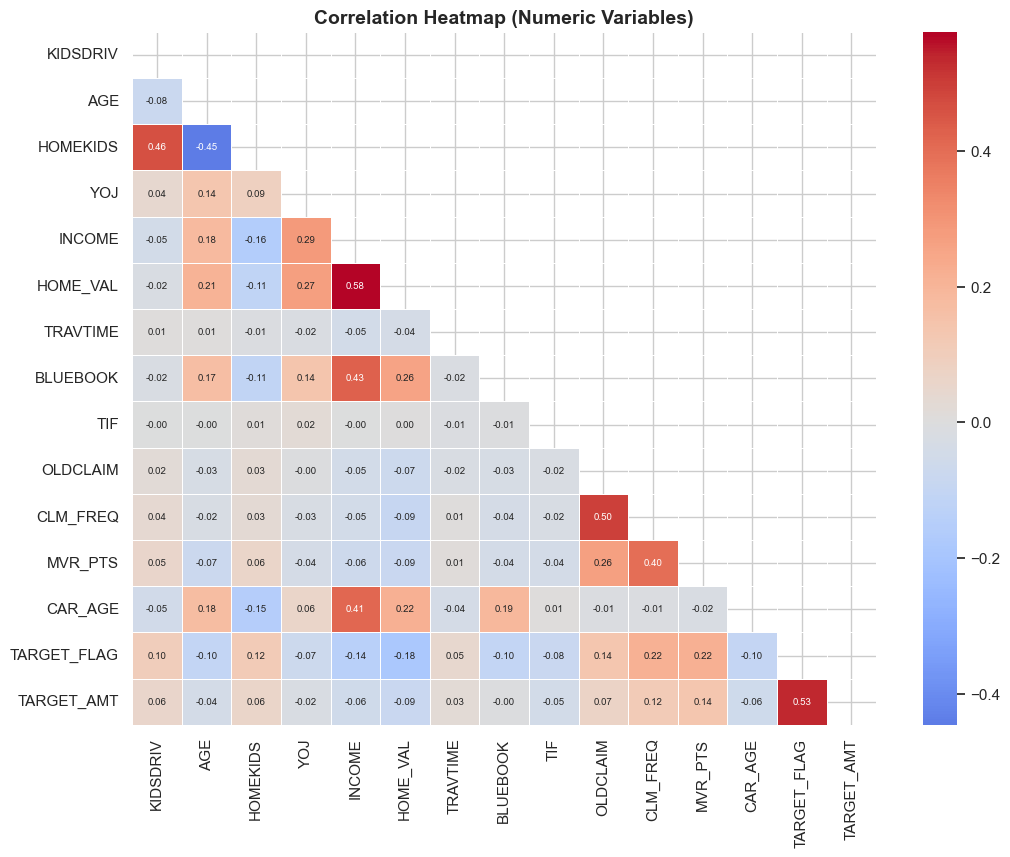

--- Strongest predictor pairs ---
INCOME    HOME_VAL    0.58
OLDCLAIM  CLM_FREQ    0.50
KIDSDRIV  HOMEKIDS    0.46
AGE       HOMEKIDS   -0.45
INCOME    BLUEBOOK    0.43
          CAR_AGE     0.41
CLM_FREQ  MVR_PTS     0.40
YOJ       INCOME      0.29


In [10]:
corr = train_df[num_cols + ["TARGET_FLAG", "TARGET_AMT"]].corr()

target_corr = corr[["TARGET_FLAG", "TARGET_AMT"]].drop(["TARGET_FLAG", "TARGET_AMT"]).sort_values("TARGET_FLAG", ascending=False).round(3)
display(target_corr)

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation Heatmap (Numeric Variables)", fontsize=14, fontweight="bold")
plt.show()

# Strongest predictor-to-predictor pairs
pairs = corr.loc[num_cols, num_cols].where(np.triu(np.ones((len(num_cols),) * 2, dtype=bool), k=1)).stack()
print("--- Strongest predictor pairs ---")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

The strongest linear correlations with a crash are driving-record variables: `MVR_PTS` (0.22) and `CLM_FREQ` (0.22), followed by `OLDCLAIM`, `HOMEKIDS` and `KIDSDRIV` (positive) and `HOME_VAL`, `INCOME` (negative). These signs agree with the theoretical effects in the assignment. Correlations with `TARGET_AMT` are weaker but have the same signs. No predictor pair exceeds 0.6 (`INCOME`/`HOME_VAL` at 0.58 is the highest), so severe multicollinearity is not expected, although `OLDCLAIM`/`CLM_FREQ` overlap by construction.

## 1.6 Missing Data Patterns

Six variables contain missing values. Before choosing an imputation strategy in Section 2, we check whether missingness is related to the outcome, which would justify creating missing-value flags.

In [11]:
miss_cols = missing.index.tolist()
rates = pd.DataFrame({
    col: train_df.groupby(train_df[col].isnull())["TARGET_FLAG"].mean() for col in miss_cols
}).T
rates.columns = ["crash rate (present)", "crash rate (missing)"]
rates["overall"] = overall
display((rates * 100).round(1))

,crash rate (present),crash rate (missing),overall
JOB,26.4,25.9,26.4
CAR_AGE,26.3,27.8,26.4
HOME_VAL,26.4,26.1,26.4
YOJ,26.3,27.1,26.4
INCOME,26.5,24.7,26.4
AGE,26.3,83.3,26.4


Six variables are missing between 0.1% and 6.5% of values (`JOB`, `CAR_AGE`, `HOME_VAL`, `YOJ`, `INCOME`, `AGE`), and the evaluation set has a similar pattern. Crash rates are nearly identical for present and missing values in every column except `AGE`, where the 6 missing customers crash far more often, but 6 records is too few to conclude anything. Missingness therefore looks essentially random, so simple median/mode imputation is reasonable; missing-value flags are optional and can be tested in Section 2.

# 2. Data Preparation

Section 1 showed what needs fixing: inconsistent `z_` prefixes, one impossible `CAR_AGE`, six variables with missing values, zero-heavy and right-skewed numerics, and a skewed crash cost. This section will check each issue and adds a few variables that capture risk more directly than the raw columns.

To avoid data leakage and to guarantee the evaluation set gets identical treatment, every statistic used (medians, caps) is learned from the training set only and applied to both sets.

## 2.1 Clean Labels and Impossible Values

- Remove the `z_` prefix from categorical levels
- Negative `CAR_AGE` is impossible; we treat it as missing so it is imputed with the other missing car ages
- `AGE` of 16 to 81 is plausible, and the zeros in `INCOME` and `HOME_VAL` are real values (unemployed, renters), so they are kept

In [12]:
def clean_labels(df):
    df = df.copy()
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.replace("z_", "", regex=False).str.strip()
    df["JOB"] = df["JOB"].replace("", np.nan)
    df.loc[df["CAR_AGE"] < 0, "CAR_AGE"] = np.nan
    return df

train_clean = clean_labels(train_df)
eval_clean = clean_labels(eval_df)

for col in ["EDUCATION", "JOB", "CAR_TYPE", "URBANICITY"]:
    print(f"{col}: {sorted(train_clean[col].dropna().unique())}")
print("Negative CAR_AGE values:", (train_clean["CAR_AGE"] < 0).sum())


EDUCATION: ['<High School', 'Bachelors', 'High School', 'Masters', 'PhD']
JOB: ['Blue Collar', 'Clerical', 'Doctor', 'Home Maker', 'Lawyer', 'Manager', 'Professional', 'Student']
CAR_TYPE: ['Minivan', 'Panel Truck', 'Pickup', 'SUV', 'Sports Car', 'Van']
URBANICITY: ['Highly Rural/ Rural', 'Highly Urban/ Urban']
Negative CAR_AGE values: 0


### 2.2 Missing Values: Flags and Imputation

Section 1.6 showed that missing values are nearly unrelated to crash risk, so simple imputation is appropriate:

- **Numeric** (`AGE`, `YOJ`, `INCOME`, `HOME_VAL`, `CAR_AGE`)  We use the median instead of the mean because these columns are skewed.
- **`JOB`**: Use a separate "Unknown" level rather than the mode, so we do not claim a job the customer may not have
- **Missing flags** (`JOB_MISSING`, `INCOME_MISSING`, `HOME_VAL_MISSING`): a 0/1 column for the three variables with the most missing values, so the model can check whether being missing matters. If it doesn't, the model will just give it a coefficient near zero

In [13]:
fill_cols = ["AGE", "YOJ", "INCOME", "HOME_VAL", "CAR_AGE"]
medians = train_clean[fill_cols].median()      # learned from training data only
print(medians.round(1).to_string())

def fill_missing(df):
    df = df.copy()
    for col in ["JOB", "INCOME", "HOME_VAL"]:
        df[f"{col}_MISSING"] = df[col].isnull().astype(int)
    df[fill_cols] = df[fill_cols].fillna(medians)
    df["JOB"] = df["JOB"].fillna("Unknown")
    return df

train_imp = fill_missing(train_clean)
eval_imp = fill_missing(eval_clean)

print("\nMissing left (train):", train_imp.drop(columns=["TARGET_AMT"]).isnull().sum().sum())
print("Missing left (eval): ", eval_imp.drop(columns=["TARGET_FLAG", "TARGET_AMT"]).isnull().sum().sum())

AGE             45.0
YOJ             11.0
INCOME       54028.0
HOME_VAL    161160.0
CAR_AGE          8.0

Missing left (train): 0
Missing left (eval):  0


### 2.3 Outliers, Transformations and New Variables

- **Capping:** Limit `INCOME`, `HOME_VAL`, `BLUEBOOK`, `OLDCLAIM`, `TRAVTIME` to their 1st and 99th percentiles since a few extreme values can pull a regression line too much
- **Square root:** Square root `SQRT_INCOME`, `SQRT_HOME_VAL`, `SQRT_BLUEBOOK` to reduce right skew. We tried log first, but it over-corrected these columns because of the zeros
- **Log:** `LOG_OLDCLAIM` since `OLDCLAIM` has the longest tail, it needs the stronger log transform
- **Zero flags:** The zero values in `HOME_OWNER`, `HAS_INCOME`, `HAS_OLDCLAIM` are real groups (renters, no income, no past claim), and renters crash more (36.9% vs 22.3% for owners)
- **Young driver flag:** `YOUNG_DRIVER` = age under 25  is a strong single flag with 57% crash rate vs 26%
- **Bucket:** We can group ages in `CAR_AGE_GROUP` by New (0-3), Mid (4-10), Old (11+) to reduce noise
- **Combined variable:** Creating a new variable by combining 2 different variables `RISK_SCORE` = `MVR_PTS` + `CLM_FREQ`

,skew before,skew after
INCOME,1.03,-0.37
HOME_VAL,0.37,-0.53
BLUEBOOK,0.63,-0.02
OLDCLAIM,3.00,0.53


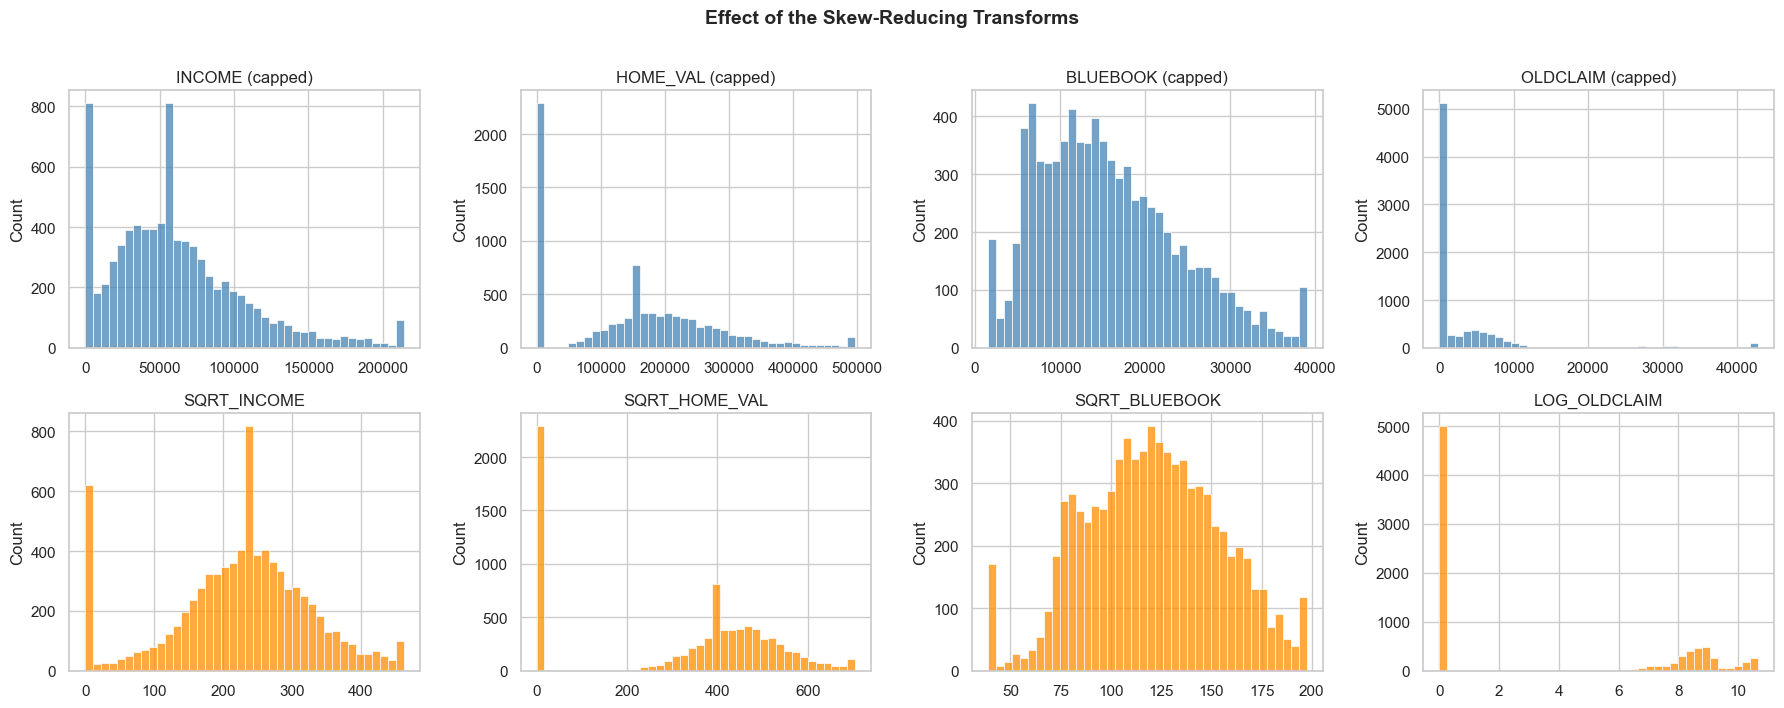

In [14]:
cap_cols = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM", "TRAVTIME"]
caps = {c: (train_imp[c].quantile(0.01), train_imp[c].quantile(0.99)) for c in cap_cols}

def transform(df):
    df = df.copy()

    # Flags (made before capping, using the original values)
    df["HOME_OWNER"] = (df["HOME_VAL"] > 0).astype(int)
    df["HAS_INCOME"] = (df["INCOME"] > 0).astype(int)
    df["HAS_OLDCLAIM"] = (df["OLDCLAIM"] > 0).astype(int)
    df["YOUNG_DRIVER"] = (df["AGE"] < 25).astype(int)

    # Cap extreme values
    for c, (low, high) in caps.items():
        df[c] = df[c].astype(float).clip(low, high)

    # Reduce skew
    for c in ["INCOME", "HOME_VAL", "BLUEBOOK"]:
        df[f"SQRT_{c}"] = np.sqrt(df[c])
    df["LOG_OLDCLAIM"] = np.log1p(df["OLDCLAIM"] )

    # Combined variable and bucket
    df["RISK_SCORE"] = df["MVR_PTS"] + df["CLM_FREQ"]
    df["CAR_AGE_GROUP"] = pd.cut(df["CAR_AGE"], [-np.inf, 3, 10, np.inf], labels=["New", "Mid", "Old"]).astype(str)
    return df

train_tf = transform(train_imp)
eval_tf = transform(eval_imp)


# Check improvement in skew
pairs = {"INCOME": "SQRT_INCOME", "HOME_VAL": "SQRT_HOME_VAL", "BLUEBOOK": "SQRT_BLUEBOOK", "OLDCLAIM": "LOG_OLDCLAIM"}
display(pd.DataFrame({
    "skew before": [train_tf[c].skew() for c in pairs],
    "skew after": [train_tf[v].skew() for v in pairs.values()],
}, index=pairs.keys()).round(2))


fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, (c, v) in enumerate(pairs.items()):
    sns.histplot(train_tf[c], bins=40, ax=axes[0, i], color="steelblue"); axes[0, i].set_title(f"{c} (capped)")
    sns.histplot(train_tf[v], bins=40, ax=axes[1, i], color="darkorange"); axes[1, i].set_title(v)
    axes[0, i].set_xlabel(""); axes[1, i].set_xlabel("")
plt.suptitle("Effect of the Skew-Reducing Transforms", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

The tails are more balanced after the transforms, and `SQRT_BLUEBOOK` is almost a bell shape. The spikes at zero in `SQRT_INCOME`, `SQRT_HOME_VAL` and `LOG_OLDCLAIM` are left purposefully. They are real groups (no income, renters, no past claim), and no transform can move a zero. That is why we added the `HAS_INCOME`, `HOME_OWNER` and `HAS_OLDCLAIM` flags. The flag handles "zero or not" and the transformed column handles "how much."

### 2.4 Check the New Variables

Before modeling, we confirm if the engineered variables actually separate risk groups to justify keeping them.

,crash rate % (0),crash rate % (1)
HOME_OWNER,36.9,22.3
HAS_INCOME,40.7,25.2
HAS_OLDCLAIM,17.9,39.8
YOUNG_DRIVER,26.1,56.9


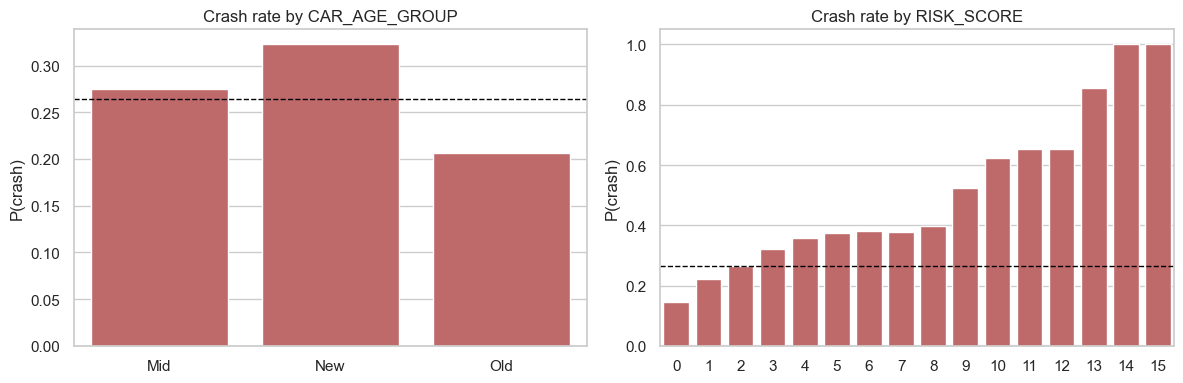

In [15]:
flags = ["HOME_OWNER", "HAS_INCOME", "HAS_OLDCLAIM", "YOUNG_DRIVER"]
check = pd.DataFrame({v: train_tf.groupby(v)["TARGET_FLAG"].mean() * 100 for v in flags}).T
check.columns = ["crash rate % (0)", "crash rate % (1)"]
display(check.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, ["CAR_AGE_GROUP", "RISK_SCORE"]):
    rate = train_tf.groupby(v)["TARGET_FLAG"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="indianred" )
    ax.axhline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Crash rate by {v}"); ax.set_ylabel("P(crash)"); ax.set_xlabel("")

plt.tight_layout()
plt.show()

All four flags show a clear gap in crash rate, the crash rate climbs with `RISK_SCORE` (about 15% at 0 to over 60% at 10+), and car age groups differ (New 32%, Mid 28%, Old 21%), so the new variables appear to be useful. The dashed line represents overall crash rate.

### 2.5 Encode Categorical Variables

Regression needs numeric inputs:

- Two-level variables become 0/1 indicators. We name them after the level we expect to be riskier (like `REVOKED`, `URBAN`), so the coefficient is easy to read
- Multi-level variables (`EDUCATION`, `JOB`, `CAR_TYPE`, `CAR_AGE_GROUP`) become one 0/1 column per level using `get_dummies`. One level is dropped as the reference group, and the other levels are compared against it. Dropping one avoids a redundant column that would break the regression
- The evaluation set is lined up to the training columns so both have the same columns

In [16]:
def encode(df):
    out = df.copy()
    out["PARENT1"] = (out["PARENT1"] =="Yes").astype(int)
    out["MSTATUS"] =(out["MSTATUS"] == "Yes").astype(int)
    out["MALE"] = (out["SEX"] == "M").astype(int)
    out["COMMERCIAL_USE"]= (out["CAR_USE"] == "Commercial" ).astype(int)
    out["RED_CAR"] = (out["RED_CAR"] == "yes").astype(int)
    out["REVOKED"] = (out["REVOKED"]=="Yes").astype(int)
    out["URBAN"]=out["URBANICITY"].str.startswith("Highly Urban").astype(int)
    out = out.drop(columns=["SEX", "CAR_USE", "URBANICITY"])
    return pd.get_dummies(out, columns=["EDUCATION", "JOB", "CAR_TYPE", "CAR_AGE_GROUP"], drop_first=True, dtype=int)

train_enc = encode(train_tf)
eval_enc = encode(eval_tf).reindex(columns=train_enc.columns, fill_value=0)

# Reference groups (the level that was dropped for each category)
for col in ["EDUCATION", "JOB","CAR_TYPE", "CAR_AGE_GROUP"]:
    print(f"Reference group for {col}: {sorted(train_tf[col].unique())[0]}" )

print(f"\nEncoded training set:{train_enc.shape}")

print(f"Encoded evaluation set:{eval_enc.shape}")

Reference group for EDUCATION: <High School
Reference group for JOB: Blue Collar
Reference group for CAR_TYPE: Minivan
Reference group for CAR_AGE_GROUP: Mid

Encoded training set:(8161, 54)
Encoded evaluation set:(2141, 54)


### 2.6 Final Modeling Datasets

For the **crash flag** models we use all customers. For the **crash cost** models we use only customers who crashed, because `TARGET_AMT` is 0 for everyone else and including them would make the model mostly predict "did they crash" instead of "how much did it cost." Crash costs are also very skewed (5.64), so we make a log version, `y_train_log_amt`, which brings the skew to about 0.

In [17]:
id_cols = ["INDEX", "TARGET_FLAG", "TARGET_AMT"]
feature_cols = [c for c in train_enc.columns if c not in id_cols]

X_train = train_enc[feature_cols ]
X_eval = eval_enc[feature_cols]
y_flag = train_enc["TARGET_FLAG"]
y_amt = train_enc["TARGET_AMT"]

# Crash cost data for crashed customers only
crash_mask = y_flag == 1
X_train_amt = X_train[crash_mask]
y_train_amt= y_amt[crash_mask]
y_train_log_amt= np.log1p(y_train_amt)

# Safety checks
assert list(X_train.columns)== list(X_eval.columns)
assert X_train.isnull().sum().sum() == 0 and X_eval.isnull().sum().sum() == 0

print(f"Predictors: {len(feature_cols)}")
print(f"Crash flag training: {X_train.shape[0]:,} rows ({y_flag.mean():.1%} crashes)")
print(f"Crash cost training:{X_train_amt.shape[0]:,} rows (crashed only) ")
print(f"Evaluation set:{X_eval.shape[0]:,} rows")
print(f"TARGET_AMT skew: {y_train_amt.skew():.2f} ")
print(f"TARGET_AMT skew after log: {y_train_log_amt.skew():.2f}" )


# Saved file for modeling
train_enc.to_csv("train_clean.csv", index=False)
eval_enc.to_csv("eval_clean.csv", index=False)

Predictors: 51
Crash flag training: 8,161 rows (26.4% crashes)
Crash cost training:2,153 rows (crashed only) 
Evaluation set:2,141 rows
TARGET_AMT skew: 5.64 
TARGET_AMT skew after log: -0.01


### 2.7 Summary

In this section we cleaned the insurance data and got it ready for modeling. We removed the `z_` prefixes from the category labels and treated the one impossible car age (-3) as missing. Missing numbers were filled with the training-set median, missing job titles were labeled "Unknown", and we added missing-value flags for `JOB`, `INCOME` and `HOME_VAL`. We capped extreme values at the 1st and 99th percentiles, then used square root transforms for `INCOME`, `HOME_VAL` and `BLUEBOOK` and a log transform for `OLDCLAIM` to reduce skew. The zero spikes that remain in those columns are real groups (no income, renters, no past claims), so we added `HOME_OWNER`, `HAS_INCOME` and `HAS_OLDCLAIM` flags to represent them. We also created `YOUNG_DRIVER` (under 25, which had a 57% crash rate versus 26%), `CAR_AGE_GROUP` buckets, and `RISK_SCORE` (`MVR_PTS` plus `CLM_FREQ`). Finally, we converted all categories to 0/1 columns, giving 51 predictors with no missing values. For the cost models, we use only customers who crashed and a log version of `TARGET_AMT`, since costs are very skewed.

# 3. Build and Select Linear Regression Models (Crash Cost)

## 3.1 Approach

The linear models predict `TARGET_AMT`, the cost of a crash. Following Section 2.6, we fit them on the 2,153 customers who crashed (`X_train_amt`), so each model estimates cost given that a crash happened. Whether a crash happens is handled by the logistic models in Section 4.

**Predictors.** Section 2 left 51 columns, but some of them carry the same information twice. Putting both versions into one regression would make the coefficients unstable or impossible to estimate, so we keep one version of each:

- For `INCOME`, `HOME_VAL`, `BLUEBOOK` and `OLDCLAIM` we use the transformed columns (`SQRT_INCOME`, `SQRT_HOME_VAL`, `SQRT_BLUEBOOK`, `LOG_OLDCLAIM`) and drop the raw ones.
- `RISK_SCORE` is exactly `MVR_PTS + CLM_FREQ`, so it cannot enter alongside them. We keep the two separate counts.
- `CAR_AGE_GROUP` is a bucketed `CAR_AGE`; we keep the numeric `CAR_AGE`.
- `JOB_MISSING` is identical to `JOB_Unknown`, so we keep only `JOB_Unknown`.

That leaves 43 candidate predictors.

**Three models.**

1. **Model 1:** raw `TARGET_AMT` on all 43 predictors. This is the baseline, in dollars.
2. **Model 2:** `log(1 + TARGET_AMT)` on all 43 predictors. Section 1 showed crash costs are heavily right-skewed (skew 5.64), and the log brings the skew to about 0 (Section 2.6).
3. **Model 3:** `log(1 + TARGET_AMT)` with predictors chosen by backward stepwise selection on AIC. Starting from all 43, we repeatedly drop the predictor whose removal lowers AIC the most, and stop when no removal lowers it further.

In [18]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

excluded = {
    "INCOME": "raw version of SQRT_INCOME",
    "HOME_VAL": "raw version of SQRT_HOME_VAL",
    "BLUEBOOK": "raw version of SQRT_BLUEBOOK",
    "OLDCLAIM": "raw version of LOG_OLDCLAIM",
    "RISK_SCORE": "exactly MVR_PTS + CLM_FREQ",
    "CAR_AGE_GROUP_New": "bucketed version of CAR_AGE",
    "CAR_AGE_GROUP_Old": "bucketed version of CAR_AGE",
    "JOB_MISSING": "identical to JOB_Unknown",
}

# confirm the duplicates before dropping them
print("RISK_SCORE == MVR_PTS + CLM_FREQ:",
      (X_train["RISK_SCORE"] == X_train["MVR_PTS"] + X_train["CLM_FREQ"]).all())
print("JOB_MISSING == JOB_Unknown:",
      (X_train["JOB_MISSING"] == X_train["JOB_Unknown"]).all())

lm_predictors = [c for c in feature_cols if c not in excluded]
print(f"\nCandidate predictors for the cost models: {len(lm_predictors)}")
print(f"Crashed customers used to fit the cost models: {len(y_train_amt):,}")

RISK_SCORE == MVR_PTS + CLM_FREQ: True
JOB_MISSING == JOB_Unknown: True

Candidate predictors for the cost models: 43
Crashed customers used to fit the cost models: 2,153


## 3.2 Fit the models

All three are ordinary least squares fits with an intercept.

In [19]:
def fit_ols(y, X, predictors):
    """Ordinary least squares with an intercept."""
    return sm.OLS(y, sm.add_constant(X[predictors], has_constant="add")).fit()

def backward_aic(y, X, predictors):
    """Backward elimination: drop the predictor whose removal lowers AIC most; stop when no removal helps."""
    current = list(predictors)
    best_aic = fit_ols(y, X, current).aic
    while len(current) > 1:
        trial = {p: fit_ols(y, X, [c for c in current if c != p]).aic for p in current}
        drop, aic = min(trial.items(), key=lambda kv: kv[1])
        if aic >= best_aic:
            break
        current.remove(drop)
        best_aic = aic
    return current

# model 1: raw cost - all candidate predictors
lm1 = fit_ols(y_train_amt, X_train_amt, lm_predictors)

# model 2: log cost - all candidate predictors
lm2 = fit_ols(y_train_log_amt, X_train_amt, lm_predictors)

# model 3: log cost - backward stepwise selection by aic
lm3_predictors = backward_aic(y_train_log_amt, X_train_amt, lm_predictors)
lm3 = fit_ols(y_train_log_amt, X_train_amt, lm3_predictors)

lm_models = {
    "Model 1: raw cost, all predictors": (lm1, lm_predictors, "raw"),
    "Model 2: log cost, all predictors": (lm2, lm_predictors, "log"),
    "Model 3: log cost, stepwise AIC": (lm3, lm3_predictors, "log"),
}
print("Model 3 predictors:", lm3_predictors)

Model 3 predictors: ['MSTATUS', 'CLM_FREQ', 'MVR_PTS', 'SQRT_BLUEBOOK', 'MALE', 'EDUCATION_Bachelors']


## 3.3 Coefficients

Models 1 and 2 have 43 predictors each, so we show only the coefficients with p < 0.10. Model 3 is shown in full.

In the log models, a coefficient `b` means a one-unit increase in the predictor multiplies the expected cost by about `exp(b)`, which is a change of `(exp(b) - 1) x 100`%, holding the other predictors fixed.

In [20]:
def coef_table(model):
    ci = model.conf_int()
    return pd.DataFrame({
        "coef": model.params,
        "std_err": model.bse,
        "t": model.tvalues,
        "p_value": model.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    })

for name, (model, preds, scale) in lm_models.items():
    table = coef_table(model)
    if len(preds) > 10:
        print(f"\n{name}: {len(preds)} predictors; showing those with p < 0.10")
        table = table[(table["p_value"] < 0.10) & (table.index != "const")]
    else:
        print(f"\n{name}: all {len(preds)} predictors")
    display(table.round(4))


Model 1: raw cost, all predictors: 43 predictors; showing those with p < 0.10


,coef,std_err,t,p_value,ci_low,ci_high
MSTATUS,-896.1256,513.7876,-1.7442,0.0813,-1903.7091,111.4579
REVOKED,-858.6067,493.2088,-1.7409,0.0819,-1825.8332,108.6199
MVR_PTS,120.8837,70.8433,1.7064,0.0881,-18.0463,259.8137
CAR_AGE,-100.8693,44.1049,-2.2870,0.0223,-187.3629,-14.3757
SQRT_BLUEBOOK,29.9240,6.9322,4.3167,0.0000,16.3293,43.5186
MALE,1344.7167,647.7504,2.0760,0.0380,74.4202,2615.0132
EDUCATION_PhD,2241.6032,1308.1275,1.7136,0.0867,-323.7518,4806.9581



Model 2: log cost, all predictors: 43 predictors; showing those with p < 0.10


,coef,std_err,t,p_value,ci_low,ci_high
MSTATUS,-0.1067,0.0539,-1.9800,0.0478,-0.2125,-0.0010
CLM_FREQ,-0.0468,0.0250,-1.8677,0.0619,-0.0959,0.0023
MVR_PTS,0.0140,0.0074,1.8830,0.0598,-0.0006,0.0286
SQRT_BLUEBOOK,0.0033,0.0007,4.5763,0.0000,0.0019,0.0048
EDUCATION_PhD,0.2457,0.1372,1.7905,0.0735,-0.0234,0.5149



Model 3: log cost, stepwise AIC: all 6 predictors


,coef,std_err,t,p_value,ci_low,ci_high
const,7.9665,0.0683,116.6911,0.0000,7.8326,8.1004
MSTATUS,-0.0785,0.0348,-2.2567,0.0241,-0.1468,-0.0103
CLM_FREQ,-0.0219,0.0146,-1.5026,0.1331,-0.0504,0.0067
MVR_PTS,0.0173,0.0070,2.4538,0.0142,0.0035,0.0311
SQRT_BLUEBOOK,0.0028,0.0005,5.5852,0.0000,0.0018,0.0038
MALE,0.0558,0.0350,1.5942,0.1110,-0.0128,0.1244
EDUCATION_Bachelors,-0.0734,0.0406,-1.8063,0.0710,-0.1530,0.0063


**Model 3 (selected below).** Interpreted as percentage changes in crash cost:

- **`SQRT_BLUEBOOK`** (+0.0028, p < 0.001) is the strongest predictor. Going from a 10,000 dollars car to a 20,000 car raises `SQRT_BLUEBOOK` by about 41, which multiplies expected cost by about 1.12 (+12%). This matches the theoretical effect: more valuable cars cost more to repair or replace.
- **`MVR_PTS`** (+0.0173, p = 0.014): each motor vehicle record point adds about 1.7% to cost. Drivers with more tickets have more expensive crashes, which makes sense.
- **`MSTATUS`** (-0.0785, p = 0.024): married customers' crashes cost about 7.6% less, consistent with the theory that married people drive more safely.
- **`MALE`** (+0.0558, p = 0.111): men's crashes cost about 5.7% more, but the effect is not significant at 0.05.
- **`EDUCATION_Bachelors`** (-0.0734, p = 0.071): about 7.1% lower cost. Because the other education dummies were removed by the stepwise search, this compares Bachelor's degree holders with all other education levels combined, not with the `<High School` reference group alone.
- **`CLM_FREQ`** (-0.0219, p = 0.133) is counterintuitive. The theory says more past claims should mean higher payouts, but the coefficient is slightly negative. Its 95% interval (-0.050 to +0.007) includes zero, so the data cannot tell this effect apart from no effect. Section 1 showed `CLM_FREQ` is one of the strongest predictors of *whether* a customer crashes; it does not seem to say much about *how much* the crash costs. Stepwise selection kept it because it lowers AIC slightly. We keep it for prediction, but its sign should not be read as evidence that past claims reduce cost.

The intercept (7.97) is the predicted log cost when every predictor is 0, including a car value of $0, so it has no practical meaning by itself.

**Models 1 and 2.** The same story appears in the full models. `SQRT_BLUEBOOK` is the only predictor with p < 0.001 in both. In Model 1, older cars have cheaper crashes (`CAR_AGE`, -101 dollars per year, p = 0.022), which fits the theory that car age affects the payout. Model 1 also has a counterintuitive negative `REVOKED` coefficient (-859 dollars, p = 0.082), which is not significant at 0.05. Model 2 shows the same negative `CLM_FREQ` sign as Model 3 (p = 0.062).

Overall, few predictors matter for cost, and the ones that do are mostly about the car (`BLUEBOOK`, `CAR_AGE`) rather than the driver. Most driver variables that predicted crashes in Section 1 do not predict how expensive the crash is.

## 3.4 Model selection

**Criteria.** We evaluate each model on the training data using what the assignment asks for: (a) mean squared error, (b) R², (c) the F-statistic, and (d) residual plots. We also use adjusted R², AIC and BIC, which penalize extra predictors.

Models 2 and 3 share the same response (log cost), so their R², adjusted R², AIC, BIC and MSE can be compared directly. Model 1 is in dollars, so its R² and AIC are not on the same scale. To compare all three on equal terms, we also convert the log-model predictions back to dollars and compute the dollar MSE and RMSE. A plain `exp()` of a log prediction underestimates the average cost, so we multiply by Duan's smearing factor (the mean of the exponentiated residuals).

In [21]:
def to_dollars(model, X, preds, scale):
    pred = np.asarray(model.predict(sm.add_constant(X[preds], has_constant="add")))
    if scale == "raw":
        return pred
    smear = np.mean(np.exp(model.resid))
    return np.exp(pred) * smear - 1

rows = []
for name, (model, preds, scale) in lm_models.items():
    dollar_pred = to_dollars(model, X_train_amt, preds, scale)
    dollar_mse = np.mean((y_train_amt.values - dollar_pred) ** 2)
    rows.append({
        "model": name,
        "response": "TARGET_AMT" if scale == "raw" else "log(1 + TARGET_AMT)",
        "predictors": len(preds),
        "R2": model.rsquared,
        "adj_R2": model.rsquared_adj,
        "F_stat": model.fvalue,
        "F_p_value": model.f_pvalue,
        "MSE (model scale)": model.mse_resid,
        "AIC": model.aic,
        "BIC": model.bic,
        "MSE ($)": dollar_mse,
        "RMSE ($)": np.sqrt(dollar_mse),
    })

lm_metrics = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(lm_metrics)

baseline_rmse = np.sqrt(np.mean((y_train_amt - y_train_amt.mean()) ** 2))
print(f"Baseline RMSE if every crash is predicted at the mean cost: ${baseline_rmse:,.0f}")

,response,predictors,R2,adj_R2,F_stat,F_p_value,MSE (model scale),AIC,BIC,MSE ($),RMSE ($)
model,,,,,,,,,,,
"Model 1: raw cost, all predictors",TARGET_AMT,43,0.0315,0.0117,1.5941,0.0087,"59,253,534.7161","44,686.4579","44,936.1411","58,042,593.9230","7,618.5690"
"Model 2: log cost, all predictors",log(1 + TARGET_AMT),43,0.0307,0.0109,1.5540,0.0125,0.6523,"5,233.5757","5,483.2589","58,689,768.0634","7,660.9248"
"Model 3: log cost, stepwise AIC",log(1 + TARGET_AMT),6,0.0223,0.0196,8.1745,0.0000,0.6466,"5,178.0802","5,217.8025","58,962,277.2492","7,678.6898"


Baseline RMSE if every crash is predicted at the mean cost: $7,741


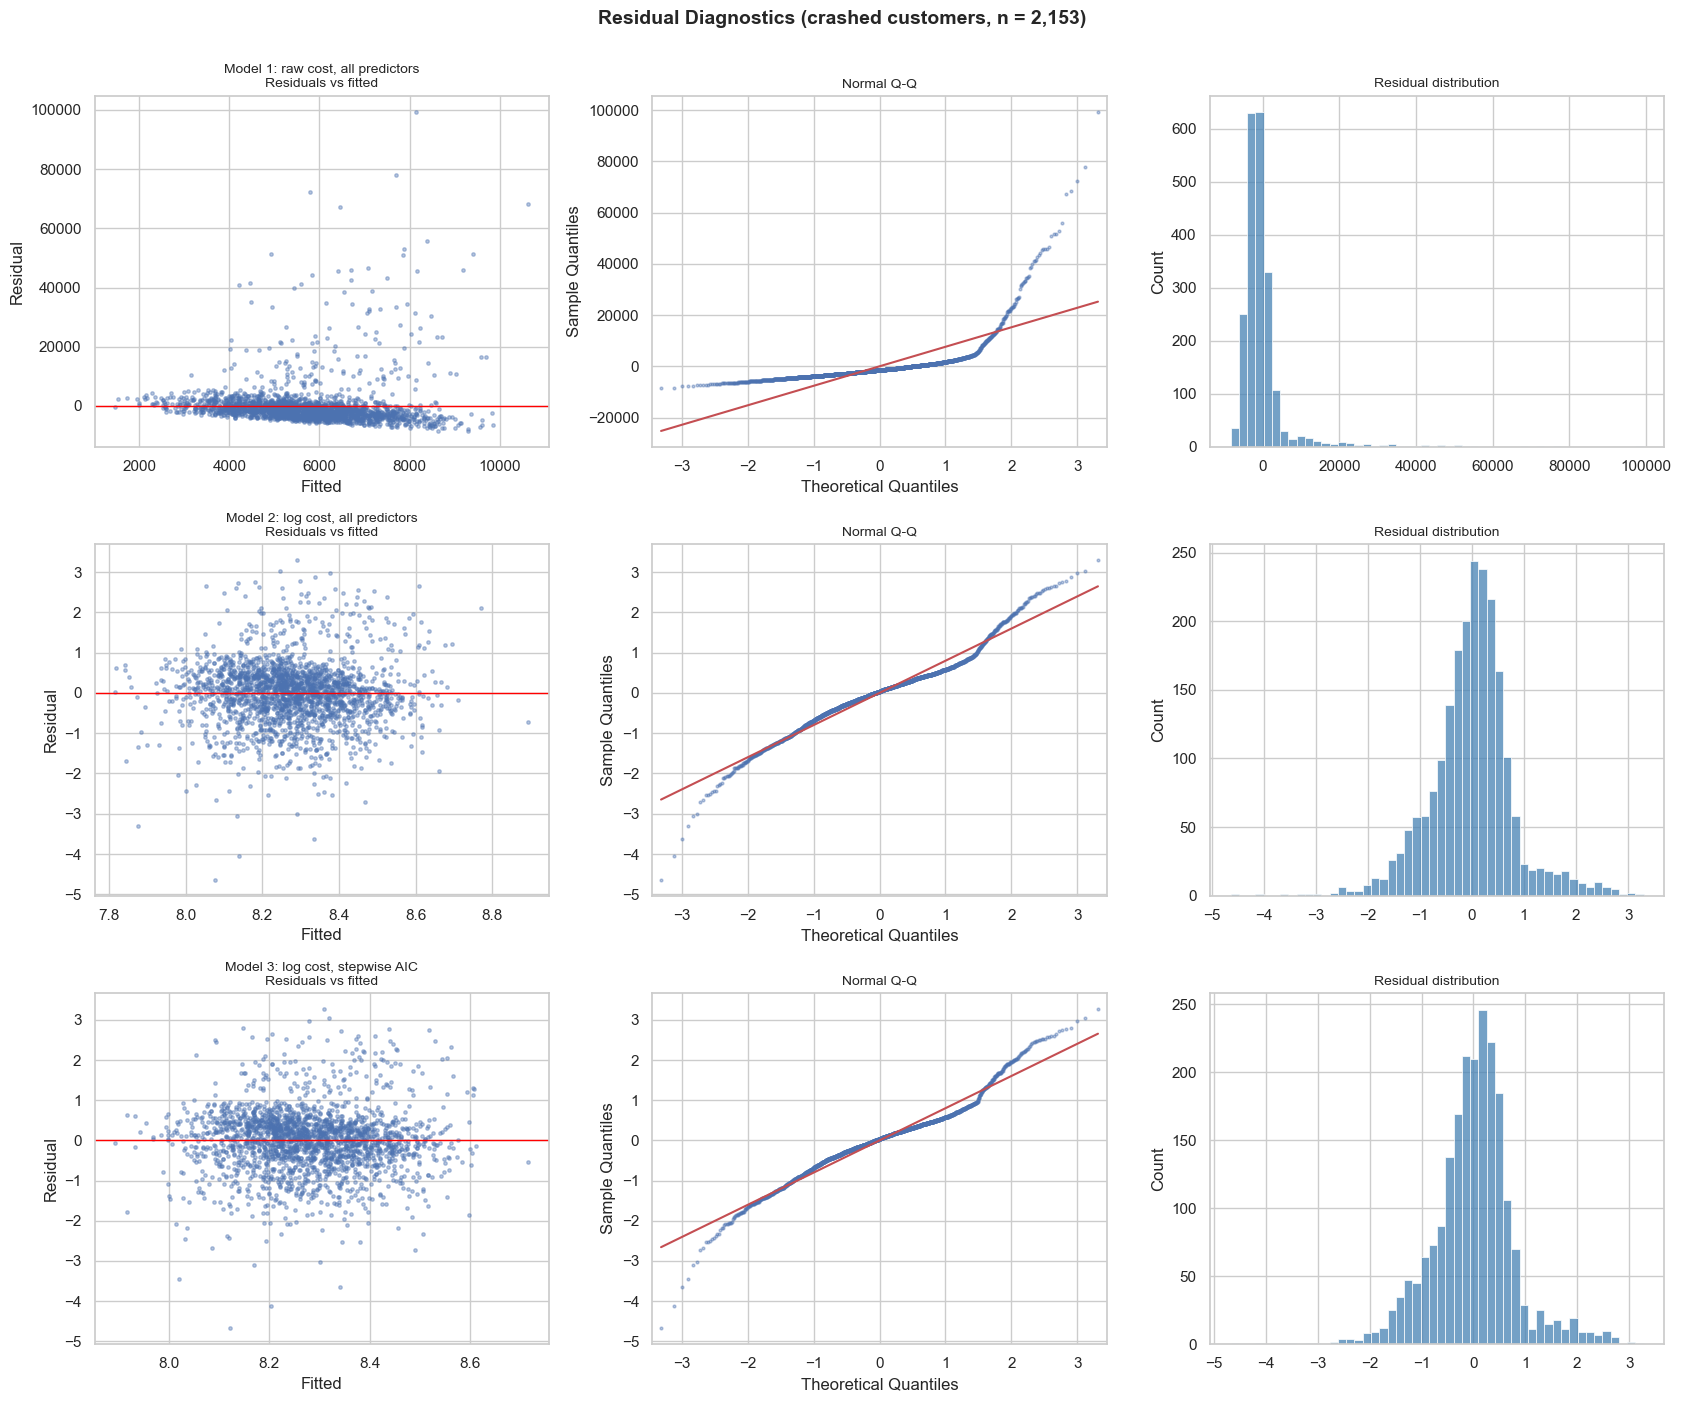

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(17, 14))
for row, (name, (model, preds, scale)) in enumerate(lm_models.items()):
    fitted, resid = model.fittedvalues, model.resid
    axes[row, 0].scatter(fitted, resid, s=6, alpha=0.4)
    axes[row, 0].axhline(0, color="red", linewidth=1)
    axes[row, 0].set_title(f"{name}\nResiduals vs fitted", fontsize=10)
    axes[row, 0].set_xlabel("Fitted"); axes[row, 0].set_ylabel("Residual")

    sm.qqplot(resid, line="s", ax=axes[row, 1], markersize=2, alpha=0.4)
    axes[row, 1].set_title("Normal Q-Q", fontsize=10)

    sns.histplot(resid, bins=50, ax=axes[row, 2], color="steelblue")
    axes[row, 2].set_title("Residual distribution", fontsize=10)

plt.suptitle("Residual Diagnostics (crashed customers, n = 2,153)", y=1.0,
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Residual plots.**

- **Model 1 (raw cost)** clearly violates the regression assumptions. The residuals are heavily right-skewed, with a long tail reaching about $100,000. The Q-Q plot bends sharply away from the line above the 1.5 quantile, and the spread of the residuals grows with the fitted value. Its t-tests, F-test and confidence intervals are therefore not reliable.
- **Models 2 and 3 (log cost)** are much better behaved. The residuals are centered on zero with roughly constant spread across fitted values, and the histogram is close to symmetric. The Q-Q plot follows the line through the middle, with heavier tails at both ends and a small bump of positive residuals between about +1 and +3 (the most expensive claims). With 2,153 observations, these departures are mild enough for the t- and F-tests to be reasonable.

The fitted values from the log models fall in a narrow band (about 7.9 to 8.7 on the log scale), which reflects how little of the cost variation the predictors explain.

In [23]:
def vif_table(X, preds):
    Xc = sm.add_constant(X[preds], has_constant="add").values
    return pd.Series(
        [variance_inflation_factor(Xc, i + 1) for i in range(len(preds))],
        index=preds, name="VIF"
    ).sort_values(ascending=False)

print("Highest VIFs, Models 1 and 2 (same predictors):")
display(vif_table(X_train_amt, lm_predictors).head(6).round(1).to_frame())

print("VIFs, Model 3:")
display(vif_table(X_train_amt, lm3_predictors).round(2).to_frame())

Highest VIFs, Models 1 and 2 (same predictors):


,VIF
HAS_OLDCLAIM,53.2
LOG_OLDCLAIM,51.0
SQRT_HOME_VAL,19.9
HOME_OWNER,19.8
SQRT_INCOME,5.9
EDUCATION_Masters,5.6


VIFs, Model 3:


,VIF
MVR_PTS,1.10
CLM_FREQ,1.10
SQRT_BLUEBOOK,1.01
EDUCATION_Bachelors,1.01
MALE,1.01
MSTATUS,1.01


**Multicollinearity.** Models 1 and 2 include pairs that measure nearly the same thing. `HAS_OLDCLAIM` and `LOG_OLDCLAIM` have VIFs of 53 and 51, because `LOG_OLDCLAIM` is 0 exactly when `HAS_OLDCLAIM` is 0. `SQRT_HOME_VAL` and `HOME_OWNER` have VIFs near 20 for the same reason. This inflates the standard errors in the full models and is one reason so few of their coefficients are significant. Every VIF in Model 3 is 1.10 or below, so its coefficients are not distorted by multicollinearity.

**Comparison.**

| Model | Predictors | R² | Adj. R² | F (p-value) | AIC | BIC | RMSE ($) |
|---|---|---|---|---|---|---|---|
| 1: raw cost, all | 43 | 0.0315 | 0.0117 | 1.59 (0.009) | 44,686 (dollar scale) | 44,936 (dollar scale) | 7,619 |
| 2: log cost, all | 43 | 0.0307 | 0.0109 | 1.55 (0.013) | 5,233.6 | 5,483.3 | 7,661 |
| 3: log cost, stepwise | 6 | 0.0223 | 0.0196 | 8.17 (< 0.001) | 5,178.1 | 5,217.8 | 7,679 |

**Decision: we select Model 3.** Between the two log models, Model 3 has the higher adjusted R² (0.0196 vs. 0.0109), lower AIC and BIC, a lower residual MSE on the log scale (0.6466 vs. 0.6523), and a much stronger F-statistic, with 6 predictors instead of 43. Model 1 has the lowest dollar RMSE (7 dollars,619 vs. 7,679 dollars), but the gap is under 1%, it comes from fitting 43 predictors to the same data it is scored on, and model 1's adjusted R² is lower than Model 3's. Model 1's residuals also violate the normality and constant-variance assumptions, so its inference cannot be trusted. We accept a slightly higher training RMSE in exchange for a simpler model with valid inference and no multicollinearity.

**Limitations.** None of the three models explains much of the crash cost. Model 3's R² is 0.022, and its dollar RMSE (7,679 dollars) is only about 1% below the 7,741 dollars we would get by predicting the average cost for every crash. The available variables say little about how severe a crash will be. The model's predictions stay in a narrow range around the average cost, so it will badly underpredict the rare very expensive claims. Also, because model 3's predictors were chosen by stepwise selection on the same data, its p-values are somewhat optimistic.

In [24]:
selected_lm = lm3
selected_lm_predictors = lm3_predictors
lm_smear = np.mean(np.exp(selected_lm.resid))

def predict_crash_cost(X):
    """Predicted cost in dollars, given that a crash happened."""
    log_pred = selected_lm.predict(sm.add_constant(X[selected_lm_predictors], has_constant="add"))
    return np.exp(np.asarray(log_pred)) * lm_smear - 1

train_cost_pred = predict_crash_cost(X_train_amt)
print(f"Smearing factor: {lm_smear:.4f}")
print(f"Mean actual cost (crashed customers):    ${y_train_amt.mean():,.0f}")
print(f"Mean predicted cost (crashed customers): ${train_cost_pred.mean():,.0f}")
print(f"Range of predicted costs: ${train_cost_pred.min():,.0f} to ${train_cost_pred.max():,.0f}")

Smearing factor: 1.4306
Mean actual cost (crashed customers):    $5,702
Mean predicted cost (crashed customers): $5,663
Range of predicted costs: $3,831 to $8,730


Model 3's back-transformed predictions average 5,663 dollars on the crashed customers, close to the actual mean of 5,702 dollars, so the smearing correction works as intended. The predictions range from about 3,800 to 8,700 dollars.


# 4. Build and Select Logistic Regression Models (Crash Probability)

## 4.1 Approach

The objective of this section is to estimate the probability that an insurance customer will experience a car crash using binary logistic regression. The response variable is `TARGET_FLAG`, where 1 represents a crash and 0 represents no crash.

Unlike the linear regression models developed in Section 3, which were fitted using only customers who experienced a crash, the logistic regression models will use all 8,161 customers in the training dataset.

Three logistic regression models will be developed:

1. **Model 1:** Full logistic regression using all 43 candidate predictors.
2. **Model 2:** Reduced logistic regression using selected predictors based on their relevance to crash risk.
3. **Model 3:** Logistic regression using statistical variable selection based on the Akaike Information Criterion (AIC).

The models will be compared using accuracy, classification error rate, precision, sensitivity, specificity, F1 score, AUC, and confusion matrices. A classification threshold of 0.5 will be applied consistently across all three models.

The final model will be selected based on predictive performance, interpretability, and model complexity.

In [25]:

import statsmodels.api as sm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# Reuse the candidate predictors from Section 3
logit_predictors = lm_predictors.copy()

# Prepare the logistic regression datasets
X_logit = X_train[logit_predictors].astype(float).copy()
y_logit = y_flag.astype(int).copy()

X_logit_eval = X_eval[logit_predictors].astype(float).copy()

# Verify modeling datasets
print("LOGISTIC REGRESSION DATA")
print("-" * 40)

print(f"Training observations: {X_logit.shape[0]:,}")
print(f"Evaluation observations: {X_logit_eval.shape[0]:,}")
print(f"Candidate predictors: {X_logit.shape[1]}")

print("\nMissing predictor values:")
print("Training:", X_logit.isna().sum().sum())
print("Evaluation:", X_logit_eval.isna().sum().sum())

# Target distribution
target_summary = pd.DataFrame({
    "Count": y_logit.value_counts().sort_index(),
    "Percentage": (
        y_logit.value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

target_summary.index = ["No Crash (0)", "Crash (1)"]

print("\nTarget Distribution:")
display(target_summary)

# Majority-class baseline
baseline_accuracy = y_logit.value_counts(
    normalize=True
).max()

print(f"\nBaseline accuracy: {baseline_accuracy:.2%}")


LOGISTIC REGRESSION DATA
----------------------------------------
Training observations: 8,161
Evaluation observations: 2,141
Candidate predictors: 43

Missing predictor values:
Training: 0
Evaluation: 0

Target Distribution:


,Count,Percentage
No Crash (0),6008,73.62
Crash (1),2153,26.38



Baseline accuracy: 73.62%


### Target Distribution and Baseline Performance

The training dataset contains 8,161 observations, of which 6,008 customers (73.62%) did not experience a crash and 2,153 customers (26.38%) experienced a crash. This indicates an imbalance in the target variable.

A baseline classifier that predicts no crash for every customer would achieve an accuracy of 73.62%. However, this approach would fail to identify customers who actually experienced a crash.

Therefore, model selection will consider multiple performance measures, particularly sensitivity, precision, F1 score, and AUC, rather than relying solely on accuracy. All models will be evaluated using a consistent classification threshold of 0.5.

The prepared training and evaluation datasets contain 43 candidate predictors with no missing values, allowing us to proceed with logistic regression modeling.

## 4.2 Model 1: Full Logistic Regression

The first logistic regression model includes all 43 candidate predictors retained following data preparation and the removal of redundant variables in Section 3.

This model serves as a reference for evaluating alternative models with fewer predictors. Maximum likelihood estimation is used to estimate the relationship between customer characteristics and the probability of experiencing a car crash.

Model coefficients, statistical significance, odds ratios, and goodness-of-fit measures will be examined to assess the relationships between the predictors and crash probability.

In [26]:

import numpy as np

# Add an intercept to the predictor matrix
X_logit_full = sm.add_constant(
    X_logit,
    has_constant="add"
)

# Fit Model 1 using all candidate predictors
logit_model1 = sm.Logit(
    y_logit,
    X_logit_full
).fit(
    maxiter=200,
    disp=False
)

# Display model summary
print("MODEL 1: FULL LOGISTIC REGRESSION")
print("=" * 60)

print(logit_model1.summary())

# Display model fit statistics
print("\nMODEL FIT STATISTICS")
print("-" * 40)

print(f"Number of predictors: {len(logit_predictors)}")
print(f"Converged: {logit_model1.mle_retvals['converged']}")
print(f"Log-Likelihood: {logit_model1.llf:.4f}")
print(f"AIC: {logit_model1.aic:.4f}")
print(f"BIC: {logit_model1.bic:.4f}")
print(f"Pseudo R-squared: {logit_model1.prsquared:.4f}")


MODEL 1: FULL LOGISTIC REGRESSION
                           Logit Regression Results                           
Dep. Variable:            TARGET_FLAG   No. Observations:                 8161
Model:                          Logit   Df Residuals:                     8117
Method:                           MLE   Df Model:                           43
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.2298
Time:                        14:40:11   Log-Likelihood:                -3626.8
converged:                       True   LL-Null:                       -4709.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.5379      0.334     -7.596      0.000      -3.193      -1.883
KIDSDRIV                  0.4044      0.061      6.575      0.00

### Model 1 Results and Interpretation

The full logistic regression model successfully converged using 8,161 observations and 43 predictor variables. The model produced a log-likelihood of -3,626.81, an AIC of 7,341.63, a BIC of 7,649.94, and a McFadden pseudo R-squared of 0.2298.

The likelihood ratio test indicates that the overall model is statistically significant (p < 0.001), suggesting that the predictors collectively improve model fit compared with an intercept-only model.

Several variables demonstrated statistically significant positive associations with crash probability, including urban location, previous claim history, license revocation, young drivers, commercial vehicle use, and certain vehicle types.

Urban location had one of the largest positive coefficients, with an estimated odds ratio of 10.75. License revocation was associated with approximately 2.33 times the odds of experiencing a crash, holding other predictors constant.

Other variables, including age, vehicle age, vehicle color, and several missing-value indicators, were not statistically significant at the 5% significance level.

Although the full model provides a useful starting point, the inclusion of numerous statistically insignificant predictors suggests that a reduced model may offer greater interpretability without substantially reducing predictive performance. This possibility will be investigated in Model 2.

## 4.3 Model 2: Reduced Logistic Regression

The second logistic regression model reduces model complexity by selecting predictors that demonstrated statistical significance in Model 1 at the 5% significance level.

For categorical predictors represented by multiple dummy variables, the corresponding group of dummy variables is retained when at least one category demonstrates statistical significance. This approach maintains consistent reference categories and supports interpretation.

The objective is to determine whether a more parsimonious model can achieve comparable predictive performance while improving interpretability and reducing unnecessary model complexity.

In [27]:

# Identify statistically significant predictors
significant_predictors = (
    logit_model1.pvalues
    .drop("const")
    .loc[lambda p: p < 0.05]
    .index.tolist()
)

# Preserve categorical predictor groups
categorical_groups = [
    "EDUCATION_",
    "JOB_",
    "CAR_TYPE_"
]

selected_predictors = set(significant_predictors)

for group in categorical_groups:
    group_columns = [
        col for col in logit_predictors
        if col.startswith(group)
    ]

    if any(
        col in selected_predictors
        for col in group_columns
    ):
        selected_predictors.update(group_columns)

# Preserve the original predictor order
logit_predictors2 = [
    col for col in logit_predictors
    if col in selected_predictors
]

# Prepare reduced predictor matrix
X_logit_reduced = sm.add_constant(
    X_logit[logit_predictors2],
    has_constant="add"
)

# Fit Model 2
logit_model2 = sm.Logit(
    y_logit,
    X_logit_reduced
).fit(
    maxiter=200,
    disp=False
)

# Display model summary
print("MODEL 2: REDUCED LOGISTIC REGRESSION")
print("=" * 60)

print(logit_model2.summary())

# Display removed predictors
removed_predictors = [
    col for col in logit_predictors
    if col not in logit_predictors2
]

print("\nREMOVED PREDICTORS")
print("-" * 40)

for col in removed_predictors:
    print(col)

# Display model fit statistics
print("\nMODEL FIT STATISTICS")
print("-" * 40)

print(f"Number of predictors: {len(logit_predictors2)}")
print(f"Predictors removed: {len(removed_predictors)}")
print(f"Converged: {logit_model2.mle_retvals['converged']}")
print(f"Log-Likelihood: {logit_model2.llf:.4f}")
print(f"AIC: {logit_model2.aic:.4f}")
print(f"BIC: {logit_model2.bic:.4f}")
print(f"Pseudo R-squared: {logit_model2.prsquared:.4f}")


MODEL 2: REDUCED LOGISTIC REGRESSION
                           Logit Regression Results                           
Dep. Variable:            TARGET_FLAG   No. Observations:                 8161
Model:                          Logit   Df Residuals:                     8128
Method:                           MLE   Df Model:                           32
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.2272
Time:                        14:40:11   Log-Likelihood:                -3638.9
converged:                       True   LL-Null:                       -4709.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.5540      0.252    -10.125      0.000      -3.048      -2.060
KIDSDRIV                  0.4314      0.055      7.823      0

### Model 2 Results and Interpretation

The reduced logistic regression model successfully converged using 8,161 observations and 32 predictors. Eleven predictors were removed based on their lack of statistical significance in Model 1, representing a 25.58% reduction in model complexity.

The removed predictors included age, number of children at home, years on the job, vehicle color, claim frequency, vehicle age, missing-value indicators, homeownership status, transformed home value, and gender.

Model 2 produced a log-likelihood of -3,638.92, an AIC of 7,343.83, a BIC of 7,575.07, and a McFadden pseudo R-squared of 0.2272.

Compared with Model 1, the reduced model demonstrated only a small decrease in pseudo R-squared. Although its AIC was slightly higher, its BIC was substantially lower, suggesting that the reduced model offers a favorable balance between model fit and complexity.

Urban location, license revocation, motor vehicle record points, commercial vehicle use, and young drivers continued to demonstrate statistically significant positive associations with crash probability.

Claim frequency was excluded because it was not statistically significant in the full model. However, previous claim history and transformed claim amounts were retained, allowing the model to continue accounting for aspects of customers' historical insurance claims.

The results suggest that a more parsimonious model may provide comparable predictive performance. Further evaluation is necessary before selecting the final logistic regression model.

## 4.4 Model 3: AIC-Based Backward Selection

The third logistic regression model uses backward variable selection based on the Akaike Information Criterion (AIC). Unlike the previous model, which relied on individual predictor significance, this approach evaluates model fit while accounting for the number of estimated parameters.

The procedure begins with all 43 candidate predictors and systematically evaluates the removal of individual predictors or categorical predictor groups. At each iteration, the removal producing the greatest reduction in AIC is accepted.

The process continues until no additional removal improves AIC. Categorical dummy variables are evaluated as groups to preserve consistent reference categories.

This approach aims to identify a parsimonious model that balances goodness of fit and model complexity while retaining relevant predictive information.

In [28]:

# Define AIC-based backward selection

def backward_aic_logit(X, y, predictors):

    remaining = predictors.copy()

    # Start with the full model
    current_model = sm.Logit(
        y,
        sm.add_constant(
            X[remaining],
            has_constant="add"
        )
    ).fit(maxiter=200, disp=False)

    current_aic = current_model.aic
    history = []

    print(f"Starting predictors: {len(remaining)}")
    print(f"Starting AIC: {current_aic:.4f}")

    categorical_groups = [
        "EDUCATION_",
        "JOB_",
        "CAR_TYPE_"
    ]

    while len(remaining) > 1:

        candidates = []
        grouped_columns = set()

        # Evaluate categorical variables as groups
        for prefix in categorical_groups:

            group = [
                col for col in remaining
                if col.startswith(prefix)
            ]

            if group:
                candidates.append(group)
                grouped_columns.update(group)

        # Evaluate other predictors individually
        for col in remaining:

            if col not in grouped_columns:
                candidates.append([col])

        best_aic = current_aic
        best_model = None
        best_removed = None
        best_predictors = None

        # Test each possible removal
        for candidate in candidates:

            trial_predictors = [
                col for col in remaining
                if col not in candidate
            ]

            if not trial_predictors:
                continue

            try:

                trial_model = sm.Logit(
                    y,
                    sm.add_constant(
                        X[trial_predictors],
                        has_constant="add"
                    )
                ).fit(maxiter=200, disp=False)

                if not trial_model.mle_retvals["converged"]:
                    continue

                if trial_model.aic < best_aic - 1e-6:

                    best_aic = trial_model.aic
                    best_model = trial_model
                    best_removed = candidate
                    best_predictors = trial_predictors

            except (np.linalg.LinAlgError, ValueError):
                continue

        # Stop when no removal improves AIC
        if best_model is None:
            break

        improvement = current_aic - best_aic

        remaining = best_predictors
        current_model = best_model
        current_aic = best_aic

        history.append({
            "Removed": ", ".join(best_removed),
            "Predictors Remaining": len(remaining),
            "AIC": current_aic,
            "AIC Improvement": improvement
        })

        print(
            f"Removed: {', '.join(best_removed)}"
            f" | AIC: {current_aic:.4f}"
        )

    return current_model, remaining, pd.DataFrame(history)


# Run backward selection
logit_model3, logit_predictors3, aic_history = (
    backward_aic_logit(
        X_logit,
        y_logit,
        logit_predictors
    )
)

# Display selection history
print("\nBACKWARD SELECTION HISTORY")
display(aic_history.round(4))

# Display final model summary
print("\nMODEL 3: AIC-SELECTED LOGISTIC REGRESSION")
print("=" * 60)

print(logit_model3.summary())

# Display final model fit statistics
print("\nMODEL FIT STATISTICS")
print("-" * 40)

print(f"Number of predictors: {len(logit_predictors3)}")
print(f"Converged: {logit_model3.mle_retvals['converged']}")
print(f"Log-Likelihood: {logit_model3.llf:.4f}")
print(f"AIC: {logit_model3.aic:.4f}")
print(f"BIC: {logit_model3.bic:.4f}")
print(f"Pseudo R-squared: {logit_model3.prsquared:.4f}")

# Display final selected predictors
print("\nSELECTED PREDICTORS")

for col in logit_predictors3:
    print(col)



Starting predictors: 43
Starting AIC: 7341.6260
Removed: AGE | AIC: 7339.6262
Removed: HOME_OWNER | AIC: 7337.6320
Removed: CAR_AGE | AIC: 7335.6394
Removed: HOME_VAL_MISSING | AIC: 7333.6816
Removed: INCOME_MISSING | AIC: 7331.8343
Removed: RED_CAR | AIC: 7330.0240
Removed: MALE | AIC: 7328.2351
Removed: HOMEKIDS | AIC: 7326.8867
Removed: CLM_FREQ | AIC: 7326.1641

BACKWARD SELECTION HISTORY


,Removed,Predictors Remaining,AIC,AIC Improvement
0,AGE,42,7339.6262,1.9998
1,HOME_OWNER,41,7337.6320,1.9942
2,CAR_AGE,40,7335.6394,1.9926
3,HOME_VAL_MISSING,39,7333.6816,1.9578
4,INCOME_MISSING,38,7331.8343,1.8474
5,RED_CAR,37,7330.0240,1.8103
6,MALE,36,7328.2351,1.7889
7,HOMEKIDS,35,7326.8867,1.3484
8,CLM_FREQ,34,7326.1641,0.7226



MODEL 3: AIC-SELECTED LOGISTIC REGRESSION
                           Logit Regression Results                           
Dep. Variable:            TARGET_FLAG   No. Observations:                 8161
Model:                          Logit   Df Residuals:                     8126
Method:                           MLE   Df Model:                           34
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.2295
Time:                        14:40:20   Log-Likelihood:                -3628.1
converged:                       True   LL-Null:                       -4709.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.4797      0.253     -9.802      0.000      -2.976      -1.984
KIDSDRIV                  0.4253      0.055      7.688 

### Model 3 Results and Interpretation

The AIC-based backward selection procedure successfully converged and reduced the number of predictors from 43 to 34. Nine predictors were removed, representing a 20.93% reduction in model complexity.

The removed predictors included age, homeownership status, vehicle age, home value and income missing-value indicators, vehicle color, gender, number of children at home, and claim frequency.

The final model produced a log-likelihood of -3,628.08, an AIC of 7,326.16, a BIC of 7,571.41, and a McFadden pseudo R-squared of 0.2295.

Model 3 achieved the lowest AIC and BIC among the three logistic regression models while maintaining a pseudo R-squared nearly identical to that of the full model. The AIC decreased by 15.46 compared with Model 1 and by 17.67 compared with Model 2.

Urban location, license revocation, commercial vehicle use, previous claim history, and vehicle type continued to demonstrate significant associations with crash probability.

Unlike Model 2, Model 3 retained years on the job and transformed home value. Although transformed home value was not statistically significant in the full model, it became significant following backward selection. This illustrates how relationships among predictors can influence coefficient estimates and statistical significance.

Based on the goodness-of-fit statistics, Model 3 appears to offer a favorable balance between model complexity and explanatory performance. However, classification performance must also be evaluated before selecting the final model.

## 4.5 Logistic Regression Model Comparison

The three logistic regression models are compared using the number of predictors, log-likelihood, AIC, BIC, and McFadden pseudo R-squared. These measures provide an initial assessment of model fit and complexity before evaluating classification performance.

In [29]:

# Store all three logistic regression models

logit_models = {
    "Model 1: Full": (
        logit_model1,
        logit_predictors
    ),
    "Model 2: Reduced": (
        logit_model2,
        logit_predictors2
    ),
    "Model 3: AIC Selection": (
        logit_model3,
        logit_predictors3
    )
}

# Compare model fit statistics

logit_comparison = []

for name, (model, predictors) in logit_models.items():

    logit_comparison.append({
        "Model": name,
        "Predictors": len(predictors),
        "Log-Likelihood": model.llf,
        "AIC": model.aic,
        "BIC": model.bic,
        "Pseudo R-squared": model.prsquared,
        "Converged": model.mle_retvals["converged"]
    })

logit_comparison_df = pd.DataFrame(
    logit_comparison
).set_index("Model")

display(logit_comparison_df.round(4))


,Predictors,Log-Likelihood,AIC,BIC,Pseudo R-squared,Converged
Model,,,,,,
Model 1: Full,43,-3626.8130,7341.6260,7649.9394,0.2298,True
Model 2: Reduced,32,-3638.9165,7343.8329,7575.0680,0.2272,True
Model 3: AIC Selection,34,-3628.0821,7326.1641,7571.4134,0.2295,True


## 4.6 Classification Performance Evaluation

The predictive performance of the three logistic regression models is evaluated using the training dataset. Predicted probabilities are converted into binary classifications using a threshold of 0.5, where probabilities greater than or equal to 0.5 are classified as a crash.

The evaluation includes accuracy, classification error rate, precision, sensitivity, specificity, F1 score, area under the ROC curve (AUC), and confusion matrices.

Because the target variable is imbalanced, accuracy alone is insufficient for determining model performance. Sensitivity, precision, F1 score, and AUC are also considered to assess the models' ability to identify customers who experienced a crash.

The results are compared against the majority-class baseline accuracy of 73.62%.

In [30]:

# Define a function to evaluate logistic regression

def evaluate_logit(model, X, y, predictors,
                   threshold=0.5):

    # Generate predicted probabilities
    probabilities = model.predict(
        sm.add_constant(
            X[predictors],
            has_constant="add"
        )
    )

    # Convert probabilities into classifications
    predictions = (
        probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate performance metrics
    accuracy = accuracy_score(y, predictions)

    metrics = {
        "Accuracy": accuracy,
        "Classification Error Rate": 1 - accuracy,
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Sensitivity": recall_score(
            y, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(
            y, predictions, zero_division=0
        ),
        "AUC": roc_auc_score(y, probabilities),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    }

    return metrics, probabilities, predictions


# Evaluate all three models

logit_metrics = []
logit_probabilities = {}
logit_predictions = {}

for name, (model, predictors) in logit_models.items():

    metrics, probabilities, predictions = (
        evaluate_logit(
            model,
            X_logit,
            y_logit,
            predictors
        )
    )

    metrics["Model"] = name

    logit_metrics.append(metrics)

    logit_probabilities[name] = probabilities
    logit_predictions[name] = predictions


# Create performance comparison table

logit_metrics_df = pd.DataFrame(
    logit_metrics
).set_index("Model")


# Display classification metrics

metric_columns = [
    "Accuracy",
    "Classification Error Rate",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1 Score",
    "AUC"
]

print("LOGISTIC REGRESSION PERFORMANCE")
print("=" * 60)

display(
    logit_metrics_df[metric_columns]
    .T.round(4)
)


# Display confusion matrix counts

confusion_columns = [
    "True Negatives",
    "False Positives",
    "False Negatives",
    "True Positives"
]

print("\nCONFUSION MATRIX RESULTS")
print("=" * 60)

display(
    logit_metrics_df[confusion_columns].T
)


# Compare accuracy against baseline

print(f"\nBaseline Accuracy: {baseline_accuracy:.2%}")

for name in logit_metrics_df.index:

    improvement = (
        logit_metrics_df.loc[name, "Accuracy"]
        - baseline_accuracy
    )

    print(
        f"{name}: "
        f"{improvement * 100:.2f} percentage points "
        "above baseline"
    )


LOGISTIC REGRESSION PERFORMANCE


Model,Model 1: Full,Model 2: Reduced,Model 3: AIC Selection
Accuracy,0.7929,0.7902,0.7924
Classification Error Rate,0.2071,0.2098,0.2076
Precision,0.6669,0.6611,0.6689
Sensitivity,0.4296,0.4203,0.4222
Specificity,0.9231,0.9228,0.9251
F1 Score,0.5226,0.5139,0.5177
AUC,0.8162,0.8150,0.8161



CONFUSION MATRIX RESULTS


Model,Model 1: Full,Model 2: Reduced,Model 3: AIC Selection
True Negatives,5546,5544,5558
False Positives,462,464,450
False Negatives,1228,1248,1244
True Positives,925,905,909



Baseline Accuracy: 73.62%
Model 1: Full: 5.67 percentage points above baseline
Model 2: Reduced: 5.40 percentage points above baseline
Model 3: AIC Selection: 5.62 percentage points above baseline


### Confusion Matrix Analysis

Confusion matrices are used to examine the classification outcomes of each logistic regression model. Particular attention is given to false negatives, which represent customers who experienced a crash but were incorrectly classified as not experiencing a crash.

False positives are also considered because they represent customers incorrectly classified as experiencing a crash. Comparing these outcomes provides additional insight into the trade-offs between identifying high-risk customers and incorrectly classifying low-risk customers.


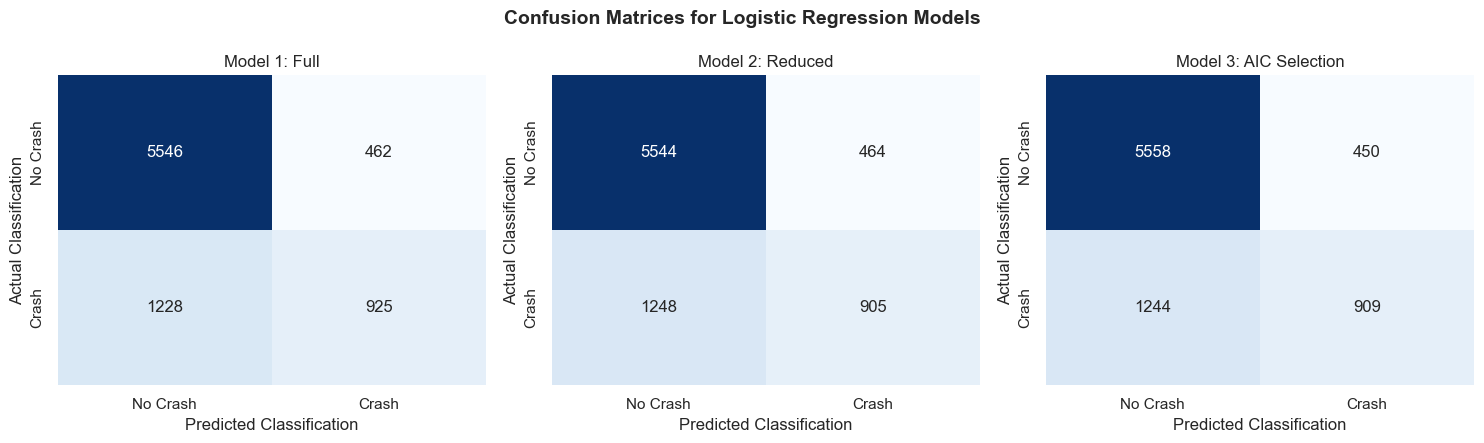

In [31]:

# Create confusion matrices for all three models

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

for ax, (name, predictions) in zip(
    axes,
    logit_predictions.items()
):

    cm = confusion_matrix(
        y_logit,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Crash", "Crash"],
        yticklabels=["No Crash", "Crash"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Classification")
    ax.set_ylabel("Actual Classification")

fig.suptitle(
    "Confusion Matrices for Logistic Regression Models",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Classification Performance Results

All three logistic regression models exceeded the baseline accuracy of 73.62%. Model 1 achieved the highest accuracy of 79.29%, followed by Model 3 at 79.24% and Model 2 at 79.02%.

Model 3 achieved the highest precision of 66.89% and specificity of 92.51%. Its confusion matrix identified 5,558 true negatives, 450 false positives, 1,244 false negatives, and 909 true positives.

Although all three models demonstrated high specificity, their sensitivity remained below 43%, indicating difficulty identifying customers who experienced a crash.

Model 3 achieved an AUC of 0.8161, which was nearly identical to Model 1's AUC of 0.8162. These results suggest that reducing the number of predictors had minimal impact on discriminatory performance within the training dataset.

## 4.7 Receiver Operating Characteristic (ROC) Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the ability of each logistic regression model to distinguish between customers who experienced a crash and those who did not.

The curve compares the true positive rate with the false positive rate across different classification thresholds. The area under the curve (AUC) summarizes the discriminatory performance of each model.

An AUC of 0.5 represents random discrimination, while an AUC of 1.0 represents perfect discrimination.

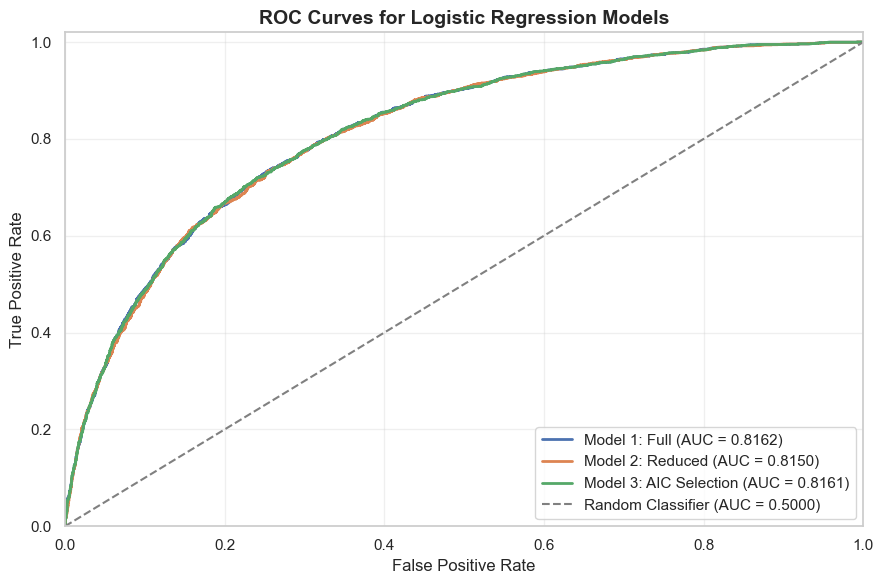

In [32]:

# Create ROC curves for all three logistic regression models

plt.figure(figsize=(9, 6))

for name, probabilities in logit_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_logit,
        probabilities
    )

    auc_value = roc_auc_score(
        y_logit,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5000)"
)

plt.title(
    "ROC Curves for Logistic Regression Models",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### ROC Curve Interpretation

The ROC curves demonstrate that all three logistic regression models achieved similar discriminatory performance. Model 1 achieved an AUC of 0.8162, Model 2 achieved an AUC of 0.8150, and Model 3 achieved an AUC of 0.8161.

All three models performed substantially better than the random classification benchmark of 0.5. The close overlap of the ROC curves indicates that reducing the number of predictors had minimal impact on the models' ability to distinguish between customers who experienced a crash and those who did not.

The difference in AUC between Model 1 and Model 3 was only 0.0001, despite Model 3 containing nine fewer predictors. These findings support the use of a more parsimonious model while maintaining comparable discriminatory performance on the training dataset.

## 4.8 Final Logistic Regression Model Selection

Based on the comparison of model fit, classification performance, and model complexity, Model 3 was selected as the final logistic regression model for predicting crash probability.

Although Model 1 achieved the highest accuracy of 79.29%, Model 3 achieved a comparable accuracy of 79.24%, representing a difference of only 0.05 percentage points. Similarly, the AUC values of 0.8162 and 0.8161 demonstrate nearly identical discriminatory performance.

Model 3 achieved the lowest AIC of 7,326.16 and BIC of 7,571.41 among the three candidate models. It also reduced the number of predictors from 43 to 34, representing a 20.93% reduction in model complexity.

Additionally, Model 3 achieved the highest precision of 66.89% and specificity of 92.51%. Although Model 2 contained fewer predictors, Model 3 demonstrated better performance across the classification metrics.

One limitation of the selected model is its sensitivity of 42.22%, indicating that a substantial proportion of actual crashes were not correctly identified at the 0.5 classification threshold. A lower classification threshold could potentially improve sensitivity but would likely increase false-positive classifications.

Another limitation is that the performance metrics were calculated using the same training dataset used to develop the models. Therefore, performance on unseen data may differ from the reported results.

Overall, Model 3 was selected because it provides a favorable balance between model fit, predictive performance, and complexity while maintaining comparable discriminatory ability to the full model.

In [33]:

# Select the final logistic regression model

selected_logit = logit_model3

selected_logit_predictors = logit_predictors3.copy()

selected_logit_name = "Model 3: AIC Selection"

# Display selected model information

print("FINAL SELECTED LOGISTIC REGRESSION MODEL")
print("=" * 60)

print(f"Selected Model: {selected_logit_name}")
print(f"Number of Predictors: {len(selected_logit_predictors)}")
print(f"AIC: {selected_logit.aic:.4f}")
print(f"BIC: {selected_logit.bic:.4f}")
print(f"Pseudo R-squared: {selected_logit.prsquared:.4f}")

# Display final model performance

print("\nFINAL MODEL PERFORMANCE")

display(
    logit_metrics_df.loc[
        selected_logit_name,
        metric_columns
    ].to_frame("Selected Model").round(4)
)


FINAL SELECTED LOGISTIC REGRESSION MODEL
Selected Model: Model 3: AIC Selection
Number of Predictors: 34
AIC: 7326.1641
BIC: 7571.4134
Pseudo R-squared: 0.2295

FINAL MODEL PERFORMANCE


,Selected Model
Accuracy,0.7924
Classification Error Rate,0.2076
Precision,0.6689
Sensitivity,0.4222
Specificity,0.9251
F1 Score,0.5177
AUC,0.8161


## 4.9 Coefficients and Odds Ratios

The coefficients of the selected logistic regression model represent the estimated change in the log-odds of experiencing a crash associated with a one-unit increase in a predictor, holding all other predictors constant.

To improve interpretability, the coefficients are converted into odds ratios by exponentiating each coefficient.

An odds ratio greater than 1 indicates an association with higher crash odds, while an odds ratio less than 1 indicates an association with lower crash odds. An odds ratio equal to 1 indicates no change in the estimated odds.

The coefficients, odds ratios, p-values, and 95% confidence intervals are examined to identify the characteristics associated with crash risk.

In [34]:

# Extract coefficients and confidence intervals
coefficients = selected_logit.params
confidence_intervals = selected_logit.conf_int()

# Create odds ratio summary table
odds_ratio_df = pd.DataFrame({
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients),
    "CI Lower (95%)": np.exp(
        confidence_intervals[0]
    ),
    "CI Upper (95%)": np.exp(
        confidence_intervals[1]
    ),
    "P-value": selected_logit.pvalues
})

# Identify statistically significant predictors
odds_ratio_df["Significant"] = np.where(
    odds_ratio_df["P-value"] < 0.05,
    "Yes",
    "No"
)

# Remove intercept from predictor interpretation
odds_ratio_df = odds_ratio_df.drop("const")

# Sort by odds ratio
odds_ratio_df = odds_ratio_df.sort_values(
    "Odds Ratio",
    ascending=False
)

print("FINAL MODEL: COEFFICIENTS AND ODDS RATIOS")
print("=" * 60)

display(odds_ratio_df.round(4))

# Display number of significant predictors
significant_count = (
    odds_ratio_df["Significant"] == "Yes"
).sum()

print(
    f"\nStatistically significant predictors: "
    f"{significant_count} out of "
    f"{len(odds_ratio_df)}"
)


FINAL MODEL: COEFFICIENTS AND ODDS RATIOS


,Coefficient,Odds Ratio,CI Lower (95%),CI Upper (95%),P-value,Significant
URBAN,2.3745,10.7453,8.5956,13.4327,0.0000,Yes
HAS_OLDCLAIM,1.7789,5.9236,2.6719,13.1325,0.0000,Yes
CAR_TYPE_Sports Car,0.9635,2.6208,2.1200,3.2399,0.0000,Yes
REVOKED,0.8463,2.3311,1.9592,2.7735,0.0000,Yes
YOUNG_DRIVER,0.7925,2.2089,1.2639,3.8605,0.0054,Yes
COMMERCIAL_USE,0.7537,2.1249,1.7738,2.5456,0.0000,Yes
CAR_TYPE_SUV,0.7266,2.0681,1.7459,2.4497,0.0000,Yes
CAR_TYPE_Van,0.6722,1.9586,1.5400,2.4909,0.0000,Yes
CAR_TYPE_Panel Truck,0.5966,1.8158,1.3586,2.4269,0.0001,Yes
CAR_TYPE_Pickup,0.5687,1.7660,1.4483,2.1535,0.0000,Yes



Statistically significant predictors: 26 out of 34


### Interpretation of Coefficients and Odds Ratios

Of the 34 predictor coefficients included in the selected logistic regression model, 26 were statistically significant at the 5% significance level.

Urban location demonstrated the largest positive coefficient, with an odds ratio of 10.7453. This indicates that customers residing in urban areas had approximately 10.75 times the estimated odds of experiencing a crash compared with customers in the reference location category, holding other predictors constant.

License revocation was associated with approximately 2.33 times the odds of experiencing a crash. Young drivers and customers using vehicles for commercial purposes also demonstrated higher crash odds, with odds ratios of 2.2089 and 2.1249, respectively.

Vehicle type was another important factor. Sports cars, SUVs, vans, panel trucks, and pickup trucks demonstrated significantly higher crash odds compared with the reference vehicle category.

Motor vehicle record points were positively associated with crash risk. Each additional motor vehicle record point was associated with an estimated 9.87% increase in crash odds, holding other predictors constant.

Several variables demonstrated negative associations with crash odds. Marital status, having income, and longer time in force were associated with lower estimated crash odds.

Previous claim history and transformed previous claim amounts were both statistically significant. Because these variables represent related aspects of insurance claim history, their coefficients should be interpreted jointly rather than independently.

Some predictors were retained despite not being individually statistically significant because the AIC-based selection procedure considers overall model fit and complexity. Categorical predictors were also retained as groups to preserve their reference categories.

These findings represent statistical associations rather than causal relationships. Furthermore, because variable selection and coefficient estimation were performed using the same training dataset, the reported p-values and confidence intervals should be interpreted with caution.

## 4.10 Evaluation Dataset Predictions

The selected AIC-based logistic regression model is applied to the evaluation dataset containing 2,141 customer observations.

Using a classification threshold of 0.5, the model classified 376 customers (17.56%) into the crash category and 1,765 customers (82.44%) into the no-crash category.

The original customer identification number (INDEX) is retained to ensure that the logistic regression predictions can be combined with the crash cost predictions generated by the selected linear regression model in Section 3.

In [35]:

# Prepare evaluation data using selected predictors

X_eval_selected = sm.add_constant(
    X_logit_eval[selected_logit_predictors],
    has_constant="add"
)

# Generate predicted crash probabilities

eval_crash_probabilities = selected_logit.predict(
    X_eval_selected
)

# Generate binary classifications

eval_crash_classifications = (
    eval_crash_probabilities >= 0.5
).astype(int)

# Create evaluation predictions table

logistic_eval_predictions = pd.DataFrame({
    "INDEX": eval_enc["INDEX"].to_numpy(),
    "Predicted_Crash_Probability":
        eval_crash_probabilities.to_numpy(),
    "Predicted_TARGET_FLAG":
        eval_crash_classifications.to_numpy()
})

# Display first 10 predictions

print("EVALUATION DATASET PREDICTIONS")
print("=" * 60)

display(logistic_eval_predictions.head(10).round(4))

# Verify prediction results

print("\nPREDICTION SUMMARY")
print("-" * 40)

print(f"Total customers: {len(logistic_eval_predictions):,}")

print(
    f"Predicted crashes: "
    f"{eval_crash_classifications.sum():,}"
)

print(
    f"Predicted no crashes: "
    f"{(eval_crash_classifications == 0).sum():,}"
)

print(
    f"Average crash probability: "
    f"{eval_crash_probabilities.mean():.2%}"
)

print(
    f"Minimum probability: "
    f"{eval_crash_probabilities.min():.4f}"
)

print(
    f"Maximum probability: "
    f"{eval_crash_probabilities.max():.4f}"
)

print(
    f"Missing values: "
    f"{logistic_eval_predictions.isna().sum().sum()}"
)

# Validate prediction results

assert len(logistic_eval_predictions) == 2141
assert logistic_eval_predictions["INDEX"].is_unique
assert logistic_eval_predictions.isna().sum().sum() == 0
assert eval_crash_probabilities.between(0, 1).all()

print("\nAll prediction validation checks passed.")


EVALUATION DATASET PREDICTIONS


,INDEX,Predicted_Crash_Probability,Predicted_TARGET_FLAG
0,3,0.1374,0
1,9,0.2647,0
2,10,0.1387,0
3,18,0.2804,0
4,21,0.1905,0
5,30,0.2720,0
6,31,0.4251,0
7,37,0.3802,0
8,39,0.0315,0
9,47,0.1179,0



PREDICTION SUMMARY
----------------------------------------
Total customers: 2,141
Predicted crashes: 376
Predicted no crashes: 1,765
Average crash probability: 27.16%
Minimum probability: 0.0030
Maximum probability: 0.9660
Missing values: 0

All prediction validation checks passed.


### Interpretation of Evaluation Predictions

The selected logistic regression model successfully generated crash probability predictions for all 2,141 customers in the evaluation dataset.

Using a classification threshold of 0.5, the model classified 376 customers (17.56%) as likely to experience a crash and 1,765 customers (82.44%) as unlikely to experience a crash.

The average predicted crash probability was 27.16%, which is relatively close to the observed crash rate of 26.38% in the training dataset. Predicted probabilities ranged from 0.30% to 96.60%, demonstrating variation in estimated crash risk across customers.

All validation checks were successfully completed, with no missing predictions, duplicate customer identification numbers, or probabilities outside the valid range of zero to one.

Because the actual crash outcomes are unavailable for the evaluation dataset, classification accuracy cannot be directly assessed.

The predicted crash probabilities and classifications are retained for integration with the selected linear regression model's crash cost predictions in the final group submission.

## 4.11 Export Logistic Regression Predictions

In [36]:

# Export logistic regression predictions

output_file = "logistic_evaluation_predictions.csv"

logistic_eval_predictions.to_csv(
    output_file,
    index=False
)

print("Predictions successfully exported.")
print(f"File name: {output_file}")
print(f"Total records: {len(logistic_eval_predictions):,}")
print(f"Total columns: {len(logistic_eval_predictions.columns)}")

# Verify exported file location

import os

print(f"\nFile location: {os.path.abspath(output_file)}")


Predictions successfully exported.
File name: logistic_evaluation_predictions.csv
Total records: 2,141
Total columns: 3

File location: /Users/ciarab/Downloads/logistic_evaluation_predictions.csv
